In [46]:
%pip install scipy
%pip install jinja2

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   -------------------- ------------------- 1/2 [jinja2]
   ---------------------------------------- 2/2 [jinja2]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
df = pd.read_csv(r"C:\Users\Keshav\Documents\py_project_delhi_pollution\csv_files\delhi_cleaned_2025.csv")
df["Timestamp"] = pd.to_datetime(df["Timestamp"])

# Categorical
df["station_name"] = df["station_name"].astype("category")
df["authority"] = df["authority"].astype("category")

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 341640 entries, 0 to 341639
Data columns (total 25 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   station_id            341640 non-null  int64         
 1   station_name          341640 non-null  category      
 2   authority             341640 non-null  category      
 3   Timestamp             341640 non-null  datetime64[us]
 4   aqi                   315235 non-null  float64       
 5   pm25                  323413 non-null  float64       
 6   pm10                  323266 non-null  float64       
 7   no                    316911 non-null  float64       
 8   no2                   327299 non-null  float64       
 9   nox                   321157 non-null  float64       
 10  nh3                   262592 non-null  float64       
 11  so2                   266923 non-null  float64       
 12  co                    315058 non-null  float64       
 13  ozone     

# Column Classification

## Numerical
- aqi
- pm25
- pm10
- no
- no2
- nox
- nh3
- so2
- co
- ozone
- benzene
- toluene
- temperature
- humidity
- wind_speed
- wind_direction
- rainfall
- total_rainfall
- solar_radiation
- atmospheric_pressure

## Categorical
- station_name
- authority

## Mixed
- station_id
- Timestamp


Missing: 0
Unique values: 3
            count  percent  stations
authority                           
DPCC       210240     61.5        24
IITM        78840     23.1         9
CPCB        52560     15.4         6


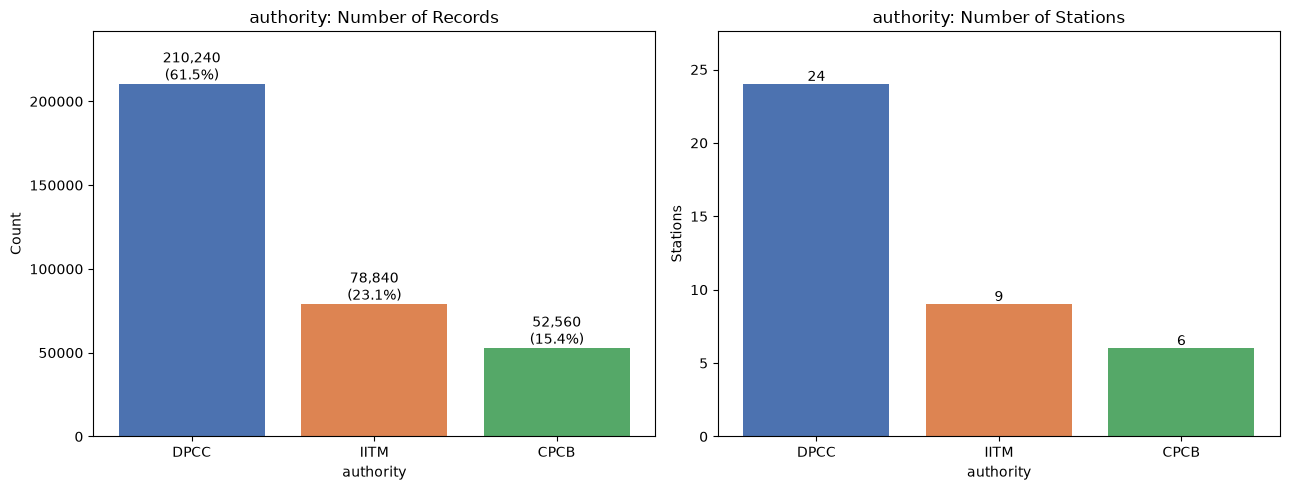

In [30]:

# ---- Summary numbers ----
print("Missing:", df["authority"].isna().sum())
print("Unique values:", df["authority"].nunique())

counts = df["authority"].value_counts()
percent = df["authority"].value_counts(normalize=True) * 100
summary = pd.DataFrame({"count": counts, "percent": percent.round(1)})
summary["stations"] = df.groupby("authority")["station_name"].nunique()
print(summary)

colors = ["#4c72b0", "#dd8452", "#55a868"]

# ---- Plots ----
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 1. Row counts with percentages
bars = axes[0].bar(counts.index, counts.values, color=colors)
for bar, c, p in zip(bars, counts.values, percent.values):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                 f"{c:,}\n({p:.1f}%)", ha="center", va="bottom")
axes[0].set_title("authority: Number of Records")
axes[0].set_xlabel("authority")
axes[0].set_ylabel("Count")
axes[0].set_ylim(0, counts.max() * 1.15)

# 2. Number of stations per authority
st = summary["stations"].reindex(counts.index)
bars = axes[1].bar(st.index, st.values, color=colors)
for bar, n in zip(bars, st.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                 str(n), ha="center", va="bottom")
axes[1].set_title("authority: Number of Stations")
axes[1].set_xlabel("authority")
axes[1].set_ylabel("Stations")
axes[1].set_ylim(0, st.max() * 1.15)

plt.tight_layout()
plt.show()


In [ ]:

df["aqi"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])

count    315235.000000
mean        199.032354
std         111.410230
min          21.000000
1%           44.000000
25%         104.000000
50%         171.000000
75%         290.000000
99%         443.000000
max         500.000000
Name: aqi, dtype: float64

Missing: 26405 (7.7%)
count    315235.000000
mean        199.032354
std         111.410230
min          21.000000
25%         104.000000
50%         171.000000
75%         290.000000
max         500.000000
Name: aqi, dtype: float64
Skewness: 0.55
Kurtosis: -0.87


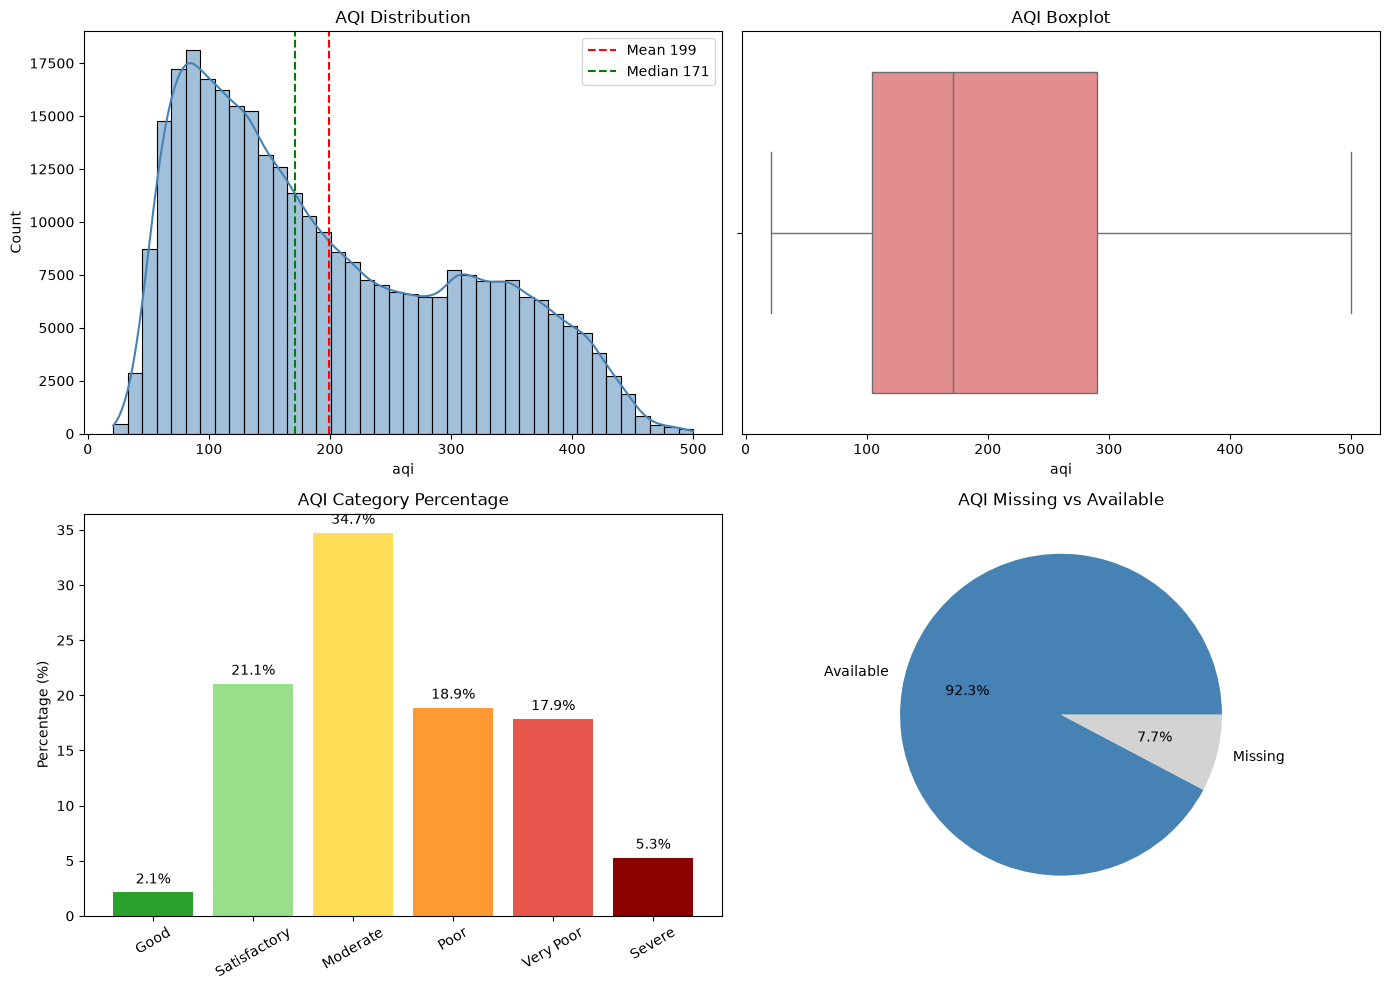

In [24]:
 #---- Summary numbers ----
print("Missing:", df["aqi"].isna().sum(), f"({df['aqi'].isna().mean()*100:.1f}%)")
print(df["aqi"].describe())
print("Skewness:", round(df["aqi"].skew(), 2))
print("Kurtosis:", round(df["aqi"].kurt(), 2))

# ---- AQI categories (CPCB bands) ----
bins = [0, 50, 100, 200, 300, 400, 500]
labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
df["aqi_category"] = pd.cut(df["aqi"], bins=bins, labels=labels)

# ---- Plots ----
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram + KDE
sns.histplot(df["aqi"].dropna(), bins=40, kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].axvline(df["aqi"].mean(), color="red", linestyle="--", label=f"Mean {df['aqi'].mean():.0f}")
axes[0, 0].axvline(df["aqi"].median(), color="green", linestyle="--", label=f"Median {df['aqi'].median():.0f}")
axes[0, 0].set_title("AQI Distribution")
axes[0, 0].legend()

# 2. Boxplot
sns.boxplot(x=df["aqi"].dropna(), ax=axes[0, 1], color="lightcoral")
axes[0, 1].set_title("AQI Boxplot")

# 3. AQI category percentages
order_pct = df["aqi_category"].value_counts(normalize=True).reindex(labels) * 100
colors = ["#2ca02c", "#98df8a", "#ffdd57", "#ff9933", "#e8574d", "#8b0000"]
bars = axes[1, 0].bar(order_pct.index.astype(str), order_pct.values, color=colors)
for bar, pct in zip(bars, order_pct.values):
    axes[1, 0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                    f"{pct:.1f}%", ha="center", va="bottom")
axes[1, 0].set_title("AQI Category Percentage")
axes[1, 0].set_ylabel("Percentage (%)")
axes[1, 0].tick_params(axis="x", rotation=30)

# 4. Missing vs available
n_missing = df["aqi"].isna().sum()
n_avail = df["aqi"].notna().sum()
axes[1, 1].pie([n_avail, n_missing], labels=["Available", "Missing"],
               autopct="%1.1f%%", colors=["steelblue", "lightgray"])
axes[1, 1].set_title("AQI Missing vs Available")

plt.tight_layout()
plt.show()


In [27]:

df["pm25"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])

count    323413.000000
mean         97.773867
std          92.477195
min           0.010000
1%            7.000000
25%          35.000000
50%          65.650000
75%         129.200000
99%         437.000000
max        1000.000000
Name: pm25, dtype: float64

Missing: 18227 (5.3%)
count    323413.000000
mean         97.773867
std          92.477195
min           0.010000
25%          35.000000
50%          65.650000
75%         129.200000
max        1000.000000
Name: pm25, dtype: float64
0.05     16.00
0.25     35.00
0.50     65.65
0.75    129.20
0.90    221.00
0.95    288.00
0.99    437.00
Name: pm25, dtype: float64
Skewness: 2.09
Kurtosis: 6.15


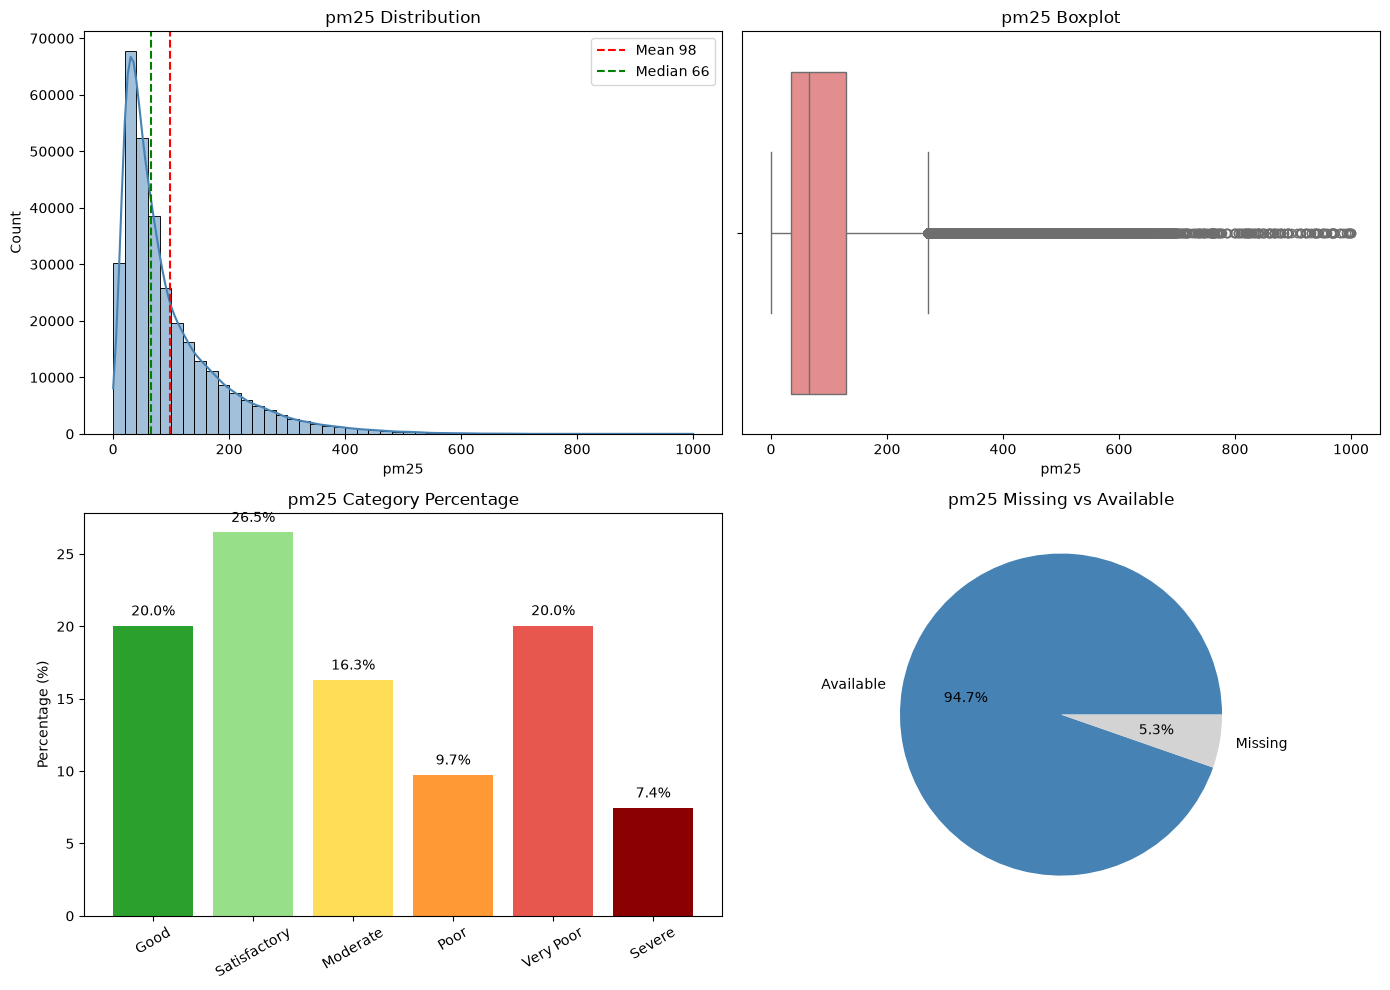

In [ ]:

# ---- Summary numbers ----
print("Missing:", df["pm25"].isna().sum(), f"({df['pm25'].isna().mean()*100:.1f}%)")
print(df["pm25"].describe())
print(df["pm25"].quantile([0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))
print("Skewness:", round(df["pm25"].skew(), 2))
print("Kurtosis:", round(df["pm25"].kurt(), 2))

# ---- pm25 categories (CPCB bands) ----
bins = [0, 30, 60, 90, 120, 250, float("inf")]
labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
df["pm25_category"] = pd.cut(df["pm25"], bins=bins, labels=labels)

# ---- Plots ----
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram + KDE
sns.histplot(df["pm25"].dropna(), bins=50, kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].axvline(df["pm25"].mean(), color="red", linestyle="--", label=f"Mean {df['pm25'].mean():.0f}")
axes[0, 0].axvline(df["pm25"].median(), color="green", linestyle="--", label=f"Median {df['pm25'].median():.0f}")
axes[0, 0].set_title("pm25 Distribution")
axes[0, 0].legend()

# 2. Boxplot
sns.boxplot(x=df["pm25"].dropna(), ax=axes[0, 1], color="lightcoral")
axes[0, 1].set_title("pm25 Boxplot")

# 3. Category percentages
order_pct = df["pm25_category"].value_counts(normalize=True).reindex(labels) * 100
colors = ["#2ca02c", "#98df8a", "#ffdd57", "#ff9933", "#e8574d", "#8b0000"]
bars = axes[1, 0].bar(order_pct.index.astype(str), order_pct.values, color=colors)
for bar, pct in zip(bars, order_pct.values):
    axes[1, 0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                    f"{pct:.1f}%", ha="center", va="bottom")
axes[1, 0].set_title("pm25 Category Percentage")
axes[1, 0].set_ylabel("Percentage (%)")
axes[1, 0].tick_params(axis="x", rotation=30)

# 4. Missing vs available
axes[1, 1].pie([df["pm25"].notna().sum(), df["pm25"].isna().sum()],
               labels=["Available", "Missing"], autopct="%1.1f%%",
               colors=["steelblue", "lightgray"])
axes[1, 1].set_title("pm25 Missing vs Available")

plt.tight_layout()
plt.show()


In [28]:

df["pm10"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])

count    323266.000000
mean        199.914208
std         139.239723
min           0.040000
1%           21.396500
25%          96.670000
50%         166.170000
75%         266.000000
99%         659.000000
max        1000.000000
Name: pm10, dtype: float64

Missing: 18374 (5.4%)
count    323266.000000
mean        199.914208
std         139.239723
min           0.040000
25%          96.670000
50%         166.170000
75%         266.000000
max        1000.000000
Name: pm10, dtype: float64
0.05     42.50
0.25     96.67
0.50    166.17
0.75    266.00
0.90    390.00
0.95    477.00
0.99    659.00
Name: pm10, dtype: float64
Skewness: 1.4
Kurtosis: 2.53


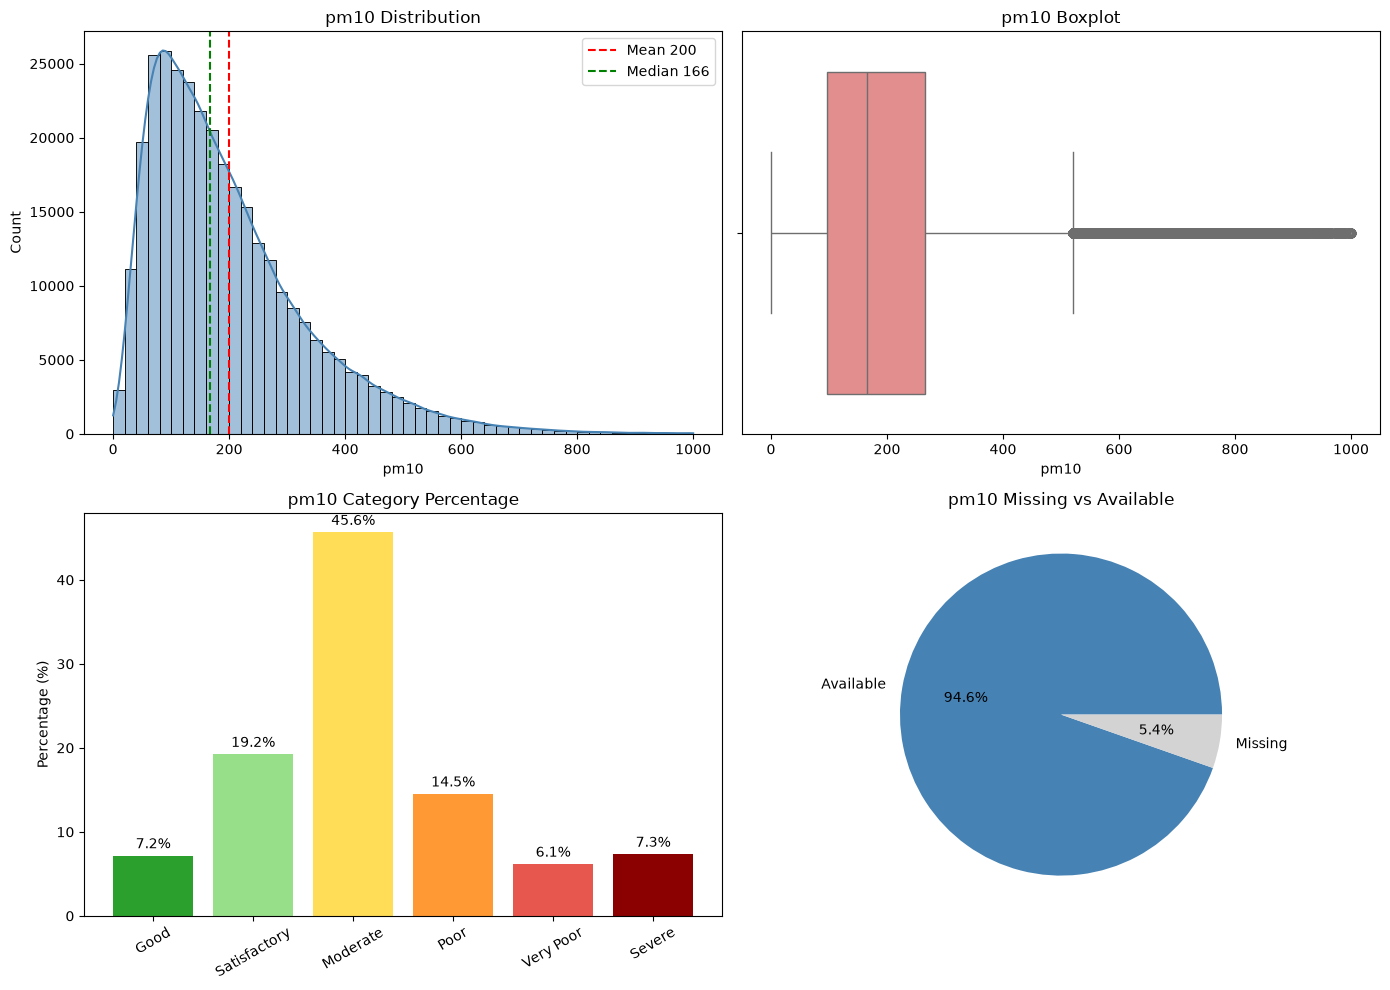

In [29]:

# ---- Summary numbers ----
print("Missing:", df["pm10"].isna().sum(), f"({df['pm10'].isna().mean()*100:.1f}%)")
print(df["pm10"].describe())
print(df["pm10"].quantile([0.05, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))
print("Skewness:", round(df["pm10"].skew(), 2))
print("Kurtosis:", round(df["pm10"].kurt(), 2))

# ---- pm10 categories (CPCB bands) ----
bins = [0, 50, 100, 250, 350, 430, float("inf")]
labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
df["pm10_category"] = pd.cut(df["pm10"], bins=bins, labels=labels)

# ---- Plots ----
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histogram + KDE
sns.histplot(df["pm10"].dropna(), bins=50, kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].axvline(df["pm10"].mean(), color="red", linestyle="--", label=f"Mean {df['pm10'].mean():.0f}")
axes[0, 0].axvline(df["pm10"].median(), color="green", linestyle="--", label=f"Median {df['pm10'].median():.0f}")
axes[0, 0].set_title("pm10 Distribution")
axes[0, 0].legend()

# 2. Boxplot
sns.boxplot(x=df["pm10"].dropna(), ax=axes[0, 1], color="lightcoral")
axes[0, 1].set_title("pm10 Boxplot")

# 3. Category percentages
order_pct = df["pm10_category"].value_counts(normalize=True).reindex(labels) * 100
colors = ["#2ca02c", "#98df8a", "#ffdd57", "#ff9933", "#e8574d", "#8b0000"]
bars = axes[1, 0].bar(order_pct.index.astype(str), order_pct.values, color=colors)
for bar, pct in zip(bars, order_pct.values):
    axes[1, 0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                    f"{pct:.1f}%", ha="center", va="bottom")
axes[1, 0].set_title("pm10 Category Percentage")
axes[1, 0].set_ylabel("Percentage (%)")
axes[1, 0].tick_params(axis="x", rotation=30)

# 4. Missing vs available
axes[1, 1].pie([df["pm10"].notna().sum(), df["pm10"].isna().sum()],
               labels=["Available", "Missing"], autopct="%1.1f%%",
               colors=["steelblue", "lightgray"])
axes[1, 1].set_title("pm10 Missing vs Available")

plt.tight_layout()
plt.show()

## Bivariate Analysis ##

    station_id                        station_name  count  missing   mean  median    std   min    max
0         1561                              Mundka   8480      280  245.2   243.0  108.7  32.0  499.0
1         1423                        Jahangirpuri   8487      273  241.1   226.0  108.3  45.0  500.0
2         1434                            Wazirpur   8571      189  245.3   221.0  111.6  49.0  499.0
3         1560                              Bawana   8583      177  220.6   212.0  122.5  31.0  498.0
4          301                         Anand Vihar   8086      674  227.5   203.0  118.0  42.0  492.0
5         1430                              Rohini   8607      153  217.6   195.0  119.1  26.0  496.0
6          119                            Sirifort   8509      251  211.3   191.0  112.3  45.0  492.0
7         1420                         Ashok Vihar   8568      192  214.1   190.0  116.9  32.0  499.0
8         1426                              Narela   8608      152  209.7   189.0 

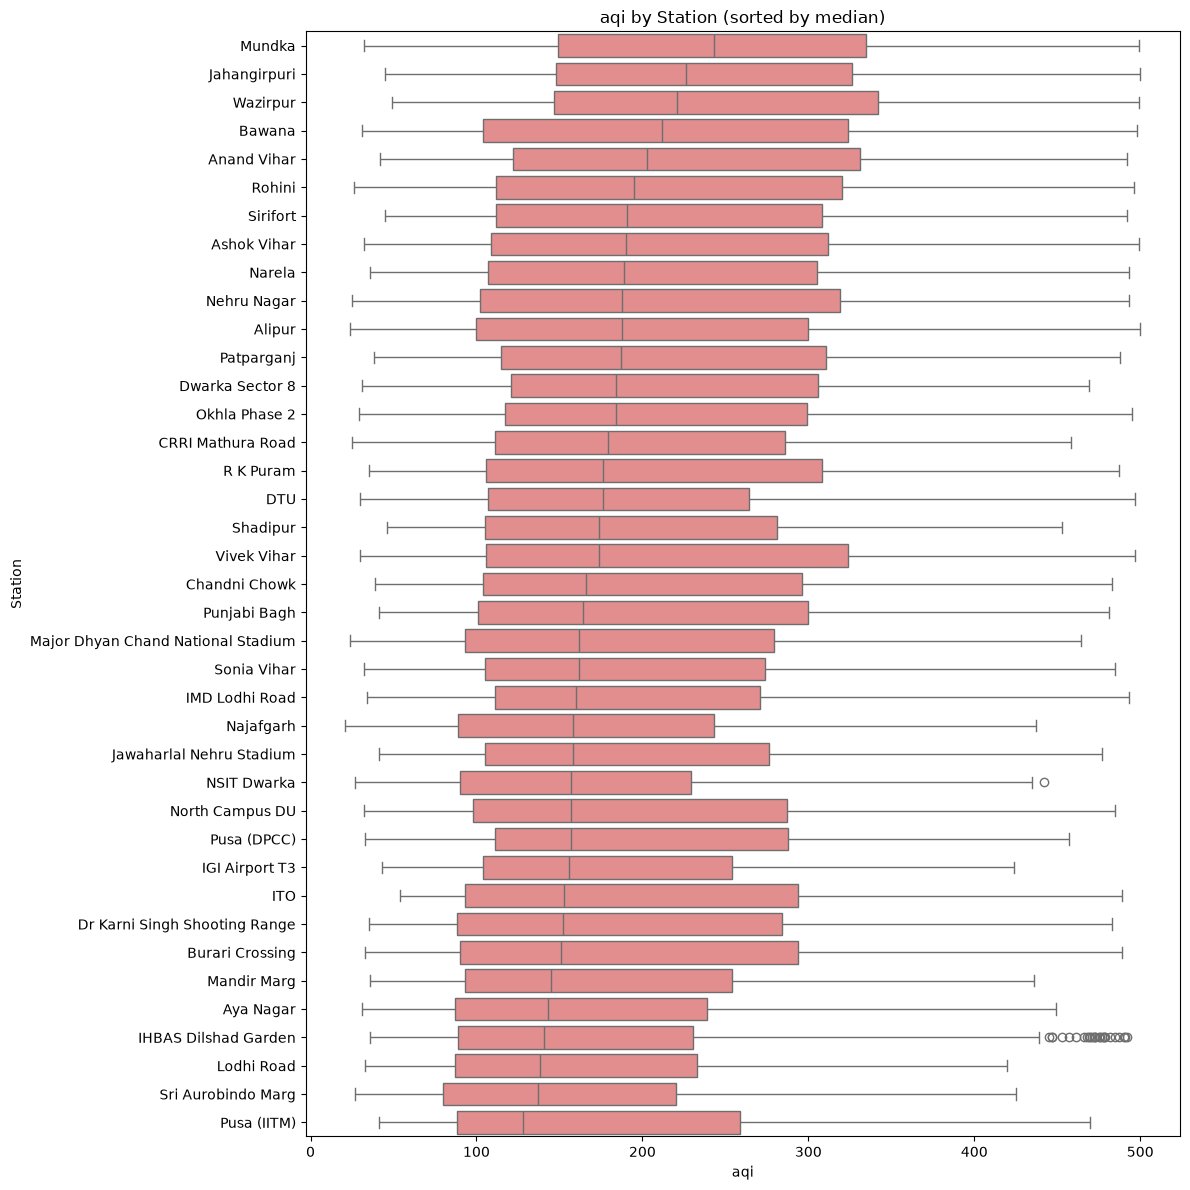

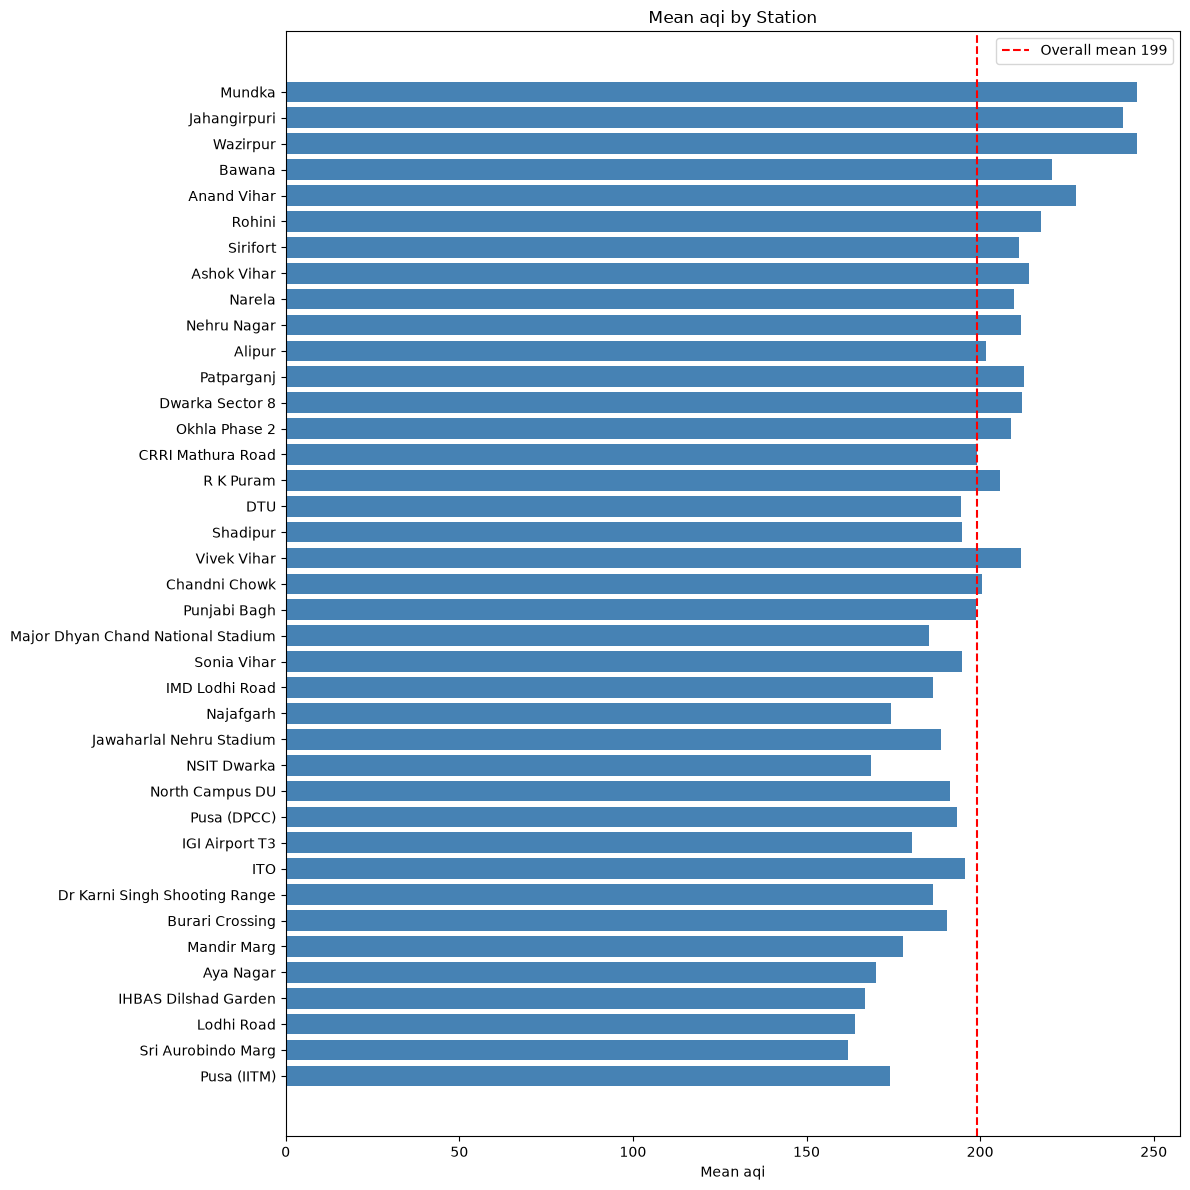

In [31]:
# ---- Summary table: aqi for each station (sorted by median) ----
summary = (df.groupby(["station_id", "station_name"])["aqi"]
             .agg(count="count", missing=lambda x: x.isna().sum(),
                  mean="mean", median="median", std="std", min="min", max="max")
             .round(1)
             .sort_values("median", ascending=False)
             .reset_index())
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 200)
print(summary)

print("\nTop 5 most polluted stations (by median aqi):")
print(summary.head(5)[["station_name", "median", "mean"]])
print("\nTop 5 least polluted stations (by median aqi):")
print(summary.tail(5)[["station_name", "median", "mean"]])

# station order: highest median aqi first
order = summary["station_name"].tolist()

# ---- Plots ----
# 1. Boxplot of aqi for every station
plt.figure(figsize=(12, 12))
sns.boxplot(data=df, y="station_name", x="aqi", order=order, color="lightcoral")
plt.title("aqi by Station (sorted by median)")
plt.xlabel("aqi")
plt.ylabel("Station")
plt.tight_layout()
plt.show()

# 2. Mean aqi per station
plt.figure(figsize=(12, 12))
mean_aqi = summary.set_index("station_name")["mean"].reindex(order)
plt.barh(mean_aqi.index, mean_aqi.values, color="steelblue")
plt.axvline(df["aqi"].mean(), color="red", linestyle="--",
            label=f"Overall mean {df['aqi'].mean():.0f}")
plt.gca().invert_yaxis()
plt.title("Mean aqi by Station")
plt.xlabel("Mean aqi")
plt.legend()
plt.tight_layout()
plt.show()


   rank authority   count  missing   mean  median   mode    std   min    max stations     level
0     1      DPCC  201713     8527  206.3   178.0  104.0  114.3  21.0  500.0       24  Moderate
1     2      CPCB   49259     3301  188.8   165.0   85.0  104.2  27.0  497.0        6  Moderate
2     3      IITM   64263    14577  184.2   153.0   86.0  105.2  25.0  493.0        9  Moderate


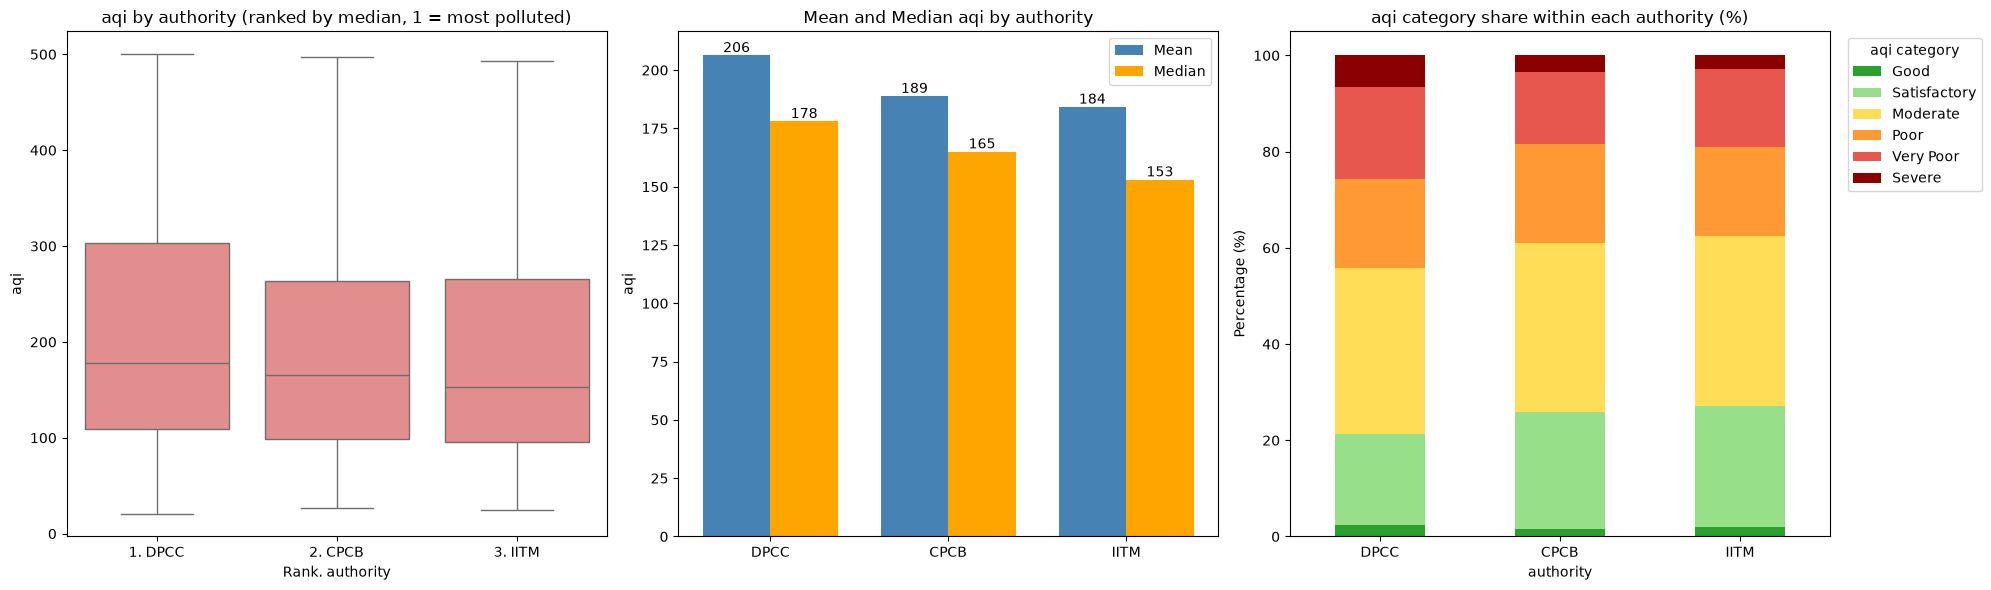


aqi category share (%) within each authority:
aqi_category  Good  Satisfactory  Moderate  Poor  Very Poor  Severe
authority                                                          
DPCC           2.3          19.0      34.5  18.6       19.1     6.5
CPCB           1.6          24.2      35.2  20.7       14.9     3.5
IITM           1.9          25.3      35.3  18.5       16.2     2.8

Skewness of aqi inside each authority:
  DPCC: 0.48
  CPCB: 0.65
  IITM: 0.65
Levene test (equal spread): statistic=840.1, p=0

Kruskal-Wallis: H=2174.3, p=0
Effect size (epsilon squared): 0.0069

Pairwise comparisons (Mann-Whitney U, Bonferroni-corrected):
  DPCC vs CPCB: p_adj=2.29e-169, P(DPCC > CPCB)=0.54
  DPCC vs IITM: p_adj=0, P(DPCC > IITM)=0.56
  CPCB vs IITM: p_adj=8.02e-21, P(CPCB > IITM)=0.52

Median aqi with 95% bootstrap confidence interval:
  DPCC: median=178  (approx. 95% CI 176 to 181)
  CPCB: median=165  (approx. 95% CI 161 to 170)
  IITM: median=153  (approx. 95% CI 150 to 157)

Station

In [38]:

# sort / rank by median (change to "mean" if you want)
sort_by = "median"

# ---- Summary table: aqi for each authority ----
summary = (df.groupby("authority")["aqi"]
             .agg(count="count", missing=lambda x: x.isna().sum(),
                  mean="mean", median="median",
                  mode=lambda x: x.mode().iloc[0],
                  std="std", min="min", max="max")
             .round(1)
             .reset_index())
summary["stations"] = summary["authority"].map(df.groupby("authority")["station_name"].nunique())

# rank: 1 = most polluted
summary = summary.sort_values([sort_by, "mean"], ascending=False).reset_index(drop=True)
summary.insert(0, "rank", range(1, len(summary) + 1))

# pollution level of each authority, based on its median aqi (CPCB bands)
bins = [0, 50, 100, 200, 300, 400, 500]
labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
summary["level"] = pd.cut(summary["median"], bins=bins, labels=labels)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
print(summary)

order = summary["authority"].tolist()
colors = ["#4c72b0", "#dd8452", "#55a868"]

# ---- Plots ----
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Boxplot of aqi for each authority
sns.boxplot(data=df, x="authority", y="aqi", order=order, color="lightcoral", ax=axes[0])
axes[0].set_title(f"aqi by authority (ranked by {sort_by}, 1 = most polluted)")
axes[0].set_xticks(range(len(order)))
axes[0].set_xticklabels([f"{r}. {a}" for r, a in zip(summary["rank"], order)])
axes[0].set_xlabel("Rank. authority")

# 2. Mean and median aqi side by side
x = np.arange(len(order))
w = 0.38
b1 = axes[1].bar(x - w / 2, summary["mean"], w, label="Mean", color="steelblue")
b2 = axes[1].bar(x + w / 2, summary["median"], w, label="Median", color="orange")
for bars in (b1, b2):
    for bar in bars:
        axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                     f"{bar.get_height():.0f}", ha="center", va="bottom")
axes[1].set_xticks(x)
axes[1].set_xticklabels(order)
axes[1].set_title("Mean and Median aqi by authority")
axes[1].set_ylabel("aqi")
axes[1].legend()

# 3. Share of each aqi category inside each authority (stacked, 100%)
df["aqi_category"] = pd.cut(df["aqi"], bins=bins, labels=labels)
pct = (pd.crosstab(df["authority"], df["aqi_category"], normalize="index") * 100).reindex(order)
cat_colors = ["#2ca02c", "#98df8a", "#ffdd57", "#ff9933", "#e8574d", "#8b0000"]
pct.plot(kind="bar", stacked=True, color=cat_colors, ax=axes[2], rot=0)
axes[2].set_title("aqi category share within each authority (%)")
axes[2].set_ylabel("Percentage (%)")
axes[2].set_xlabel("authority")
axes[2].legend(title="aqi category", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

print("\naqi category share (%) within each authority:")
print(pct.round(1))


# =====================================================================
# Statistical tests: are the differences between authorities real?
# =====================================================================
from scipy import stats
from itertools import combinations

groups = {a: df.loc[df["authority"] == a, "aqi"].dropna() for a in order}

# 1. Check normality-ish and equal spread (explains why we use non-parametric tests)
print("\nSkewness of aqi inside each authority:")
for a, g in groups.items():
    print(f"  {a}: {g.skew():.2f}")
lev = stats.levene(*groups.values())
print(f"Levene test (equal spread): statistic={lev.statistic:.1f}, p={lev.pvalue:.3g}")

# 2. Kruskal-Wallis: do the 3 authorities differ at all?
kw = stats.kruskal(*groups.values())
n_total = sum(len(g) for g in groups.values())
k = len(groups)
epsilon_sq = (kw.statistic - k + 1) / (n_total - k)   # effect size (0 = none, 1 = huge)
print(f"\nKruskal-Wallis: H={kw.statistic:.1f}, p={kw.pvalue:.3g}")
print(f"Effect size (epsilon squared): {epsilon_sq:.4f}")

# 3. Pairwise Mann-Whitney U with Bonferroni correction
pairs = list(combinations(order, 2))
print("\nPairwise comparisons (Mann-Whitney U, Bonferroni-corrected):")
for a, b in pairs:
    u = stats.mannwhitneyu(groups[a], groups[b], alternative="two-sided")
    p_adj = min(u.pvalue * len(pairs), 1.0)
    # effect size: probability that a random reading from a is higher than from b
    prob = u.statistic / (len(groups[a]) * len(groups[b]))
    print(f"  {a} vs {b}: p_adj={p_adj:.3g}, P({a} > {b})={prob:.2f}")

# 4. Bootstrap 95% confidence interval for the median of each authority
#    (each draw uses 10% of the rows: hourly readings are correlated, so this is more cautious than using all rows)
rng = np.random.default_rng(42)
print("\nMedian aqi with 95% bootstrap confidence interval:")
for a, g in groups.items():
    meds = [np.median(rng.choice(g.values, size=len(g) // 10, replace=True)) for _ in range(1000)]
    lo, hi = np.percentile(meds, [2.5, 97.5])
    print(f"  {a}: median={g.median():.0f}  (approx. 95% CI {lo:.0f} to {hi:.0f})")

# 5. Robustness check: compare at station level (each station counts once)
station_median = df.groupby(["authority", "station_name"])["aqi"].median().reset_index()
print("\nStation-level median aqi inside each authority:")
print(station_median.groupby("authority")["aqi"].describe()[["count", "mean", "min", "max"]].round(1).reindex(order))

### Time Series Analysis of Aqi ###

In [39]:
df["Timestamp"] = pd.to_datetime(df["Timestamp"])
df["month"] = df["Timestamp"].dt.month
df["hour"] = df["Timestamp"].dt.hour
df["weekday"] = df["Timestamp"].dt.day_name()

season_map = {12: "Winter", 1: "Winter", 2: "Winter",
              3: "Summer", 4: "Summer", 5: "Summer",
              6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
              10: "Post-monsoon", 11: "Post-monsoon"}
df["season"] = df["month"].map(season_map)

print(df[["Timestamp", "month", "hour", "weekday", "season"]].head())

            Timestamp  month  hour    weekday  season
0 2025-01-01 00:00:00      1     0  Wednesday  Winter
1 2025-01-01 01:00:00      1     1  Wednesday  Winter
2 2025-01-01 02:00:00      1     2  Wednesday  Winter
3 2025-01-01 03:00:00      1     3  Wednesday  Winter
4 2025-01-01 04:00:00      1     4  Wednesday  Winter


In [40]:
print("Date range:", df["Timestamp"].min(), "to", df["Timestamp"].max())
print("Duplicate station-hour rows:", df.duplicated(["station_id", "Timestamp"]).sum())

rows = df.groupby("station_name").size()
print("Rows per station -> min:", rows.min(), "max:", rows.max())

print(df["season"].value_counts())

Date range: 2025-01-01 00:00:00 to 2025-12-31 23:00:00
Duplicate station-hour rows: 0
Rows per station -> min: 8760 max: 8760
season
Monsoon         114192
Summer           86112
Winter           84240
Post-monsoon     57096
Name: count, dtype: int64


        mean  median
month               
1      305.0   308.0
2      213.0   205.0
3      165.0   157.0
4      202.0   208.0
5      162.0   153.0
6      136.0   129.0
7       78.0    78.0
8       89.0    89.0
9      104.0   111.0
10     218.0   231.0
11     353.0   364.0
12     352.0   358.0
               mean  median
season                     
Winter        292.0   301.0
Summer        176.0   170.0
Monsoon       101.0    92.0
Post-monsoon  285.0   309.0


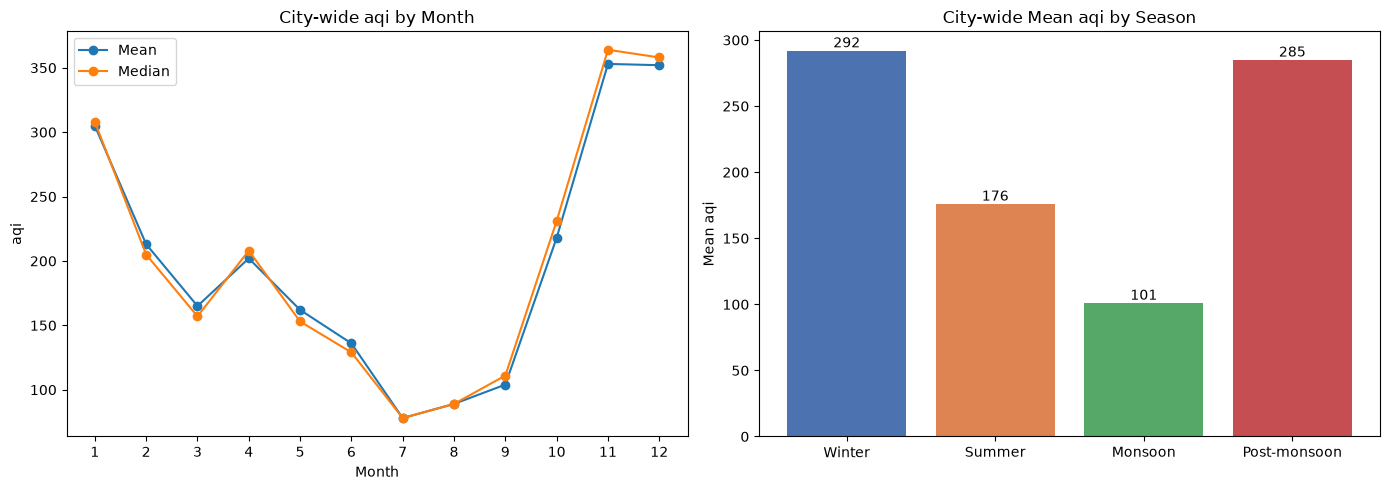

In [41]:
city = df.groupby("Timestamp", as_index=False)["aqi"].mean()
city["month"] = city["Timestamp"].dt.month
city["season"] = city["month"].map(season_map)

monthly = city.groupby("month")["aqi"].agg(["mean", "median"]).round(0)
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
seasonal = city.groupby("season")["aqi"].agg(["mean", "median"]).round(0).reindex(season_order)
print(monthly)
print(seasonal)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(monthly.index, monthly["mean"], marker="o", label="Mean")
axes[0].plot(monthly.index, monthly["median"], marker="o", label="Median")
axes[0].set_xticks(range(1, 13))
axes[0].set_title("City-wide aqi by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("aqi")
axes[0].legend()

axes[1].bar(seasonal.index, seasonal["mean"], color=["#4c72b0", "#dd8452", "#55a868", "#c44e52"])
for i, v in enumerate(seasonal["mean"]):
    axes[1].text(i, v, f"{v:.0f}", ha="center", va="bottom")
axes[1].set_title("City-wide Mean aqi by Season")
axes[1].set_ylabel("Mean aqi")

plt.tight_layout()
plt.show()

hour       0      1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23
mean    197.0  197.0  196.0  198.0  196.0  196.0  196.0  196.0  196.0  196.0  197.0  198.0  199.0  200.0  200.0  201.0  201.0  200.0  200.0  199.0  199.0  199.0  198.0  197.0
median  173.0  173.0  174.0  174.0  172.0  171.0  168.0  170.0  169.0  169.0  170.0  169.0  173.0  179.0  179.0  182.0  180.0  181.0  181.0  175.0  177.0  178.0  176.0  175.0
            mean  median
weekday                 
Monday     199.0   179.0
Tuesday    200.0   193.0
Wednesday  201.0   198.0
Thursday   198.0   177.0
Friday     196.0   166.0
Saturday   194.0   160.0
Sunday     199.0   166.0


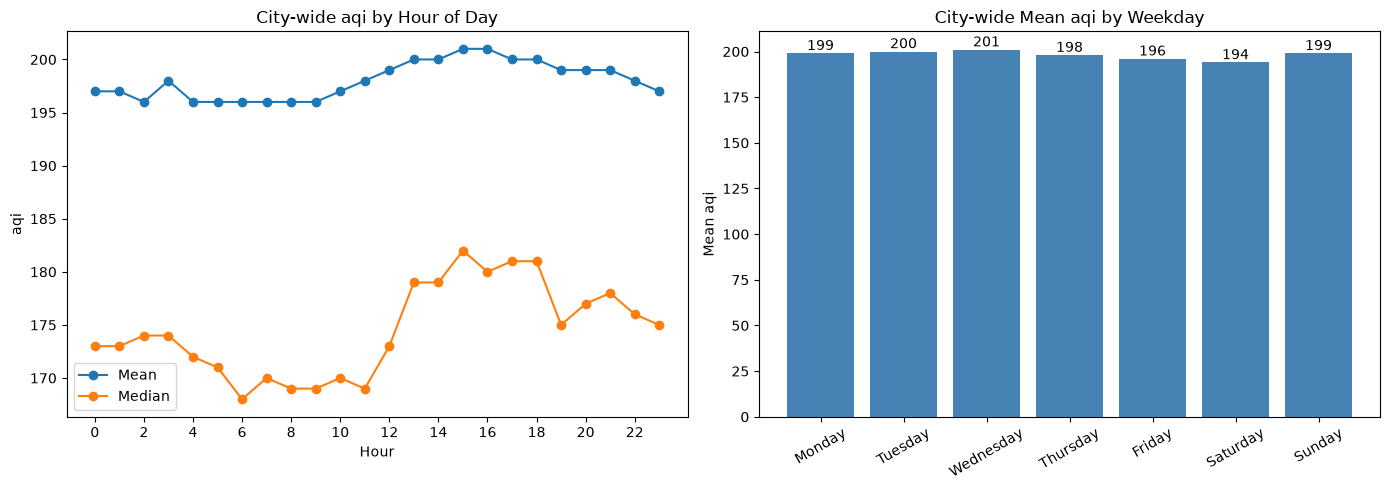

In [42]:
city = df.groupby("Timestamp", as_index=False)["aqi"].mean()
city["hour"] = city["Timestamp"].dt.hour
city["weekday"] = city["Timestamp"].dt.day_name()

hourly = city.groupby("hour")["aqi"].agg(["mean", "median"]).round(0)
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekly = city.groupby("weekday")["aqi"].agg(["mean", "median"]).round(0).reindex(day_order)
print(hourly.T)
print(weekly)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(hourly.index, hourly["mean"], marker="o", label="Mean")
axes[0].plot(hourly.index, hourly["median"], marker="o", label="Median")
axes[0].set_xticks(range(0, 24, 2))
axes[0].set_title("City-wide aqi by Hour of Day")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("aqi")
axes[0].legend()

axes[1].bar(weekly.index, weekly["mean"], color="steelblue")
for i, v in enumerate(weekly["mean"]):
    axes[1].text(i, v, f"{v:.0f}", ha="center", va="bottom")
axes[1].set_title("City-wide Mean aqi by Weekday")
axes[1].set_ylabel("Mean aqi")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

authority   CPCB   DPCC   IITM
month                         
1          263.0  321.0  272.0
2          203.0  223.0  187.0
3          155.0  172.0  150.0
4          189.0  210.0  183.0
5          160.0  166.0  151.0
6          133.0  141.0  123.0
7           74.0   80.0   72.0
8           84.0   91.0   88.0
9           93.0  108.0  100.0
10         203.0  226.0  206.0
11         324.0  367.0  336.0
12         347.0  363.0  324.0
authority      CPCB   DPCC   IITM
season                           
Winter        273.0  305.0  263.0
Summer        168.0  182.0  161.0
Monsoon        96.0  105.0   95.0
Post-monsoon  263.0  295.0  270.0


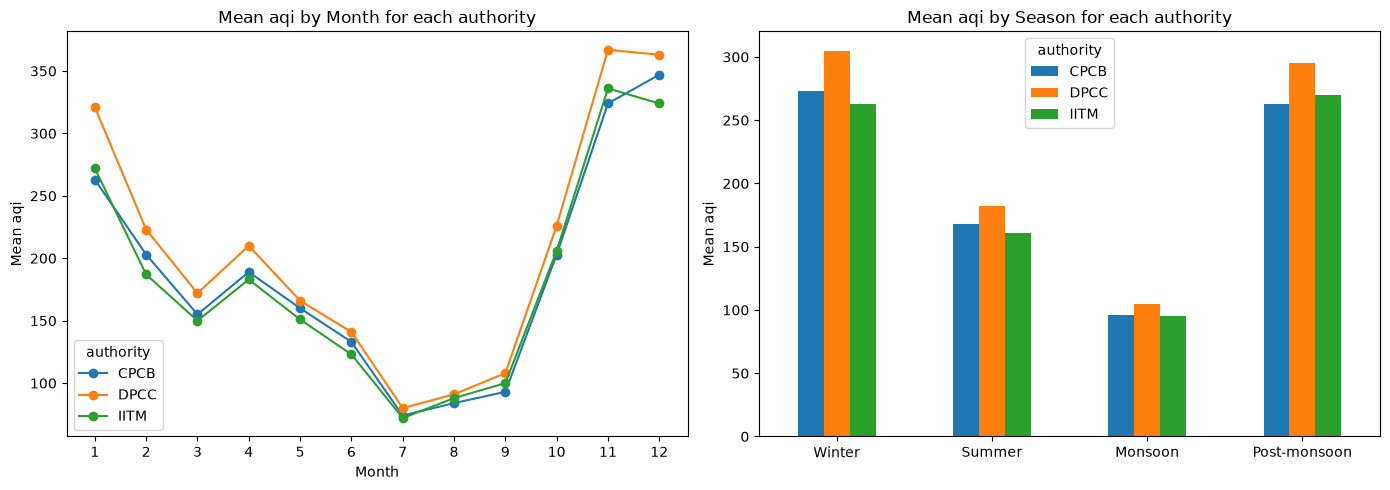

In [43]:
auth = df.groupby(["authority", "Timestamp"], as_index=False)["aqi"].mean()
auth["month"] = auth["Timestamp"].dt.month
auth["season"] = auth["month"].map(season_map)

monthly = auth.pivot_table(index="month", columns="authority", values="aqi", aggfunc="mean").round(0)
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
seasonal = auth.pivot_table(index="season", columns="authority", values="aqi", aggfunc="mean").round(0).reindex(season_order)
print(monthly)
print(seasonal)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

monthly.plot(ax=axes[0], marker="o")
axes[0].set_xticks(range(1, 13))
axes[0].set_title("Mean aqi by Month for each authority")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Mean aqi")

seasonal.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Mean aqi by Season for each authority")
axes[1].set_xlabel("")
axes[1].set_ylabel("Mean aqi")

plt.tight_layout()
plt.show()

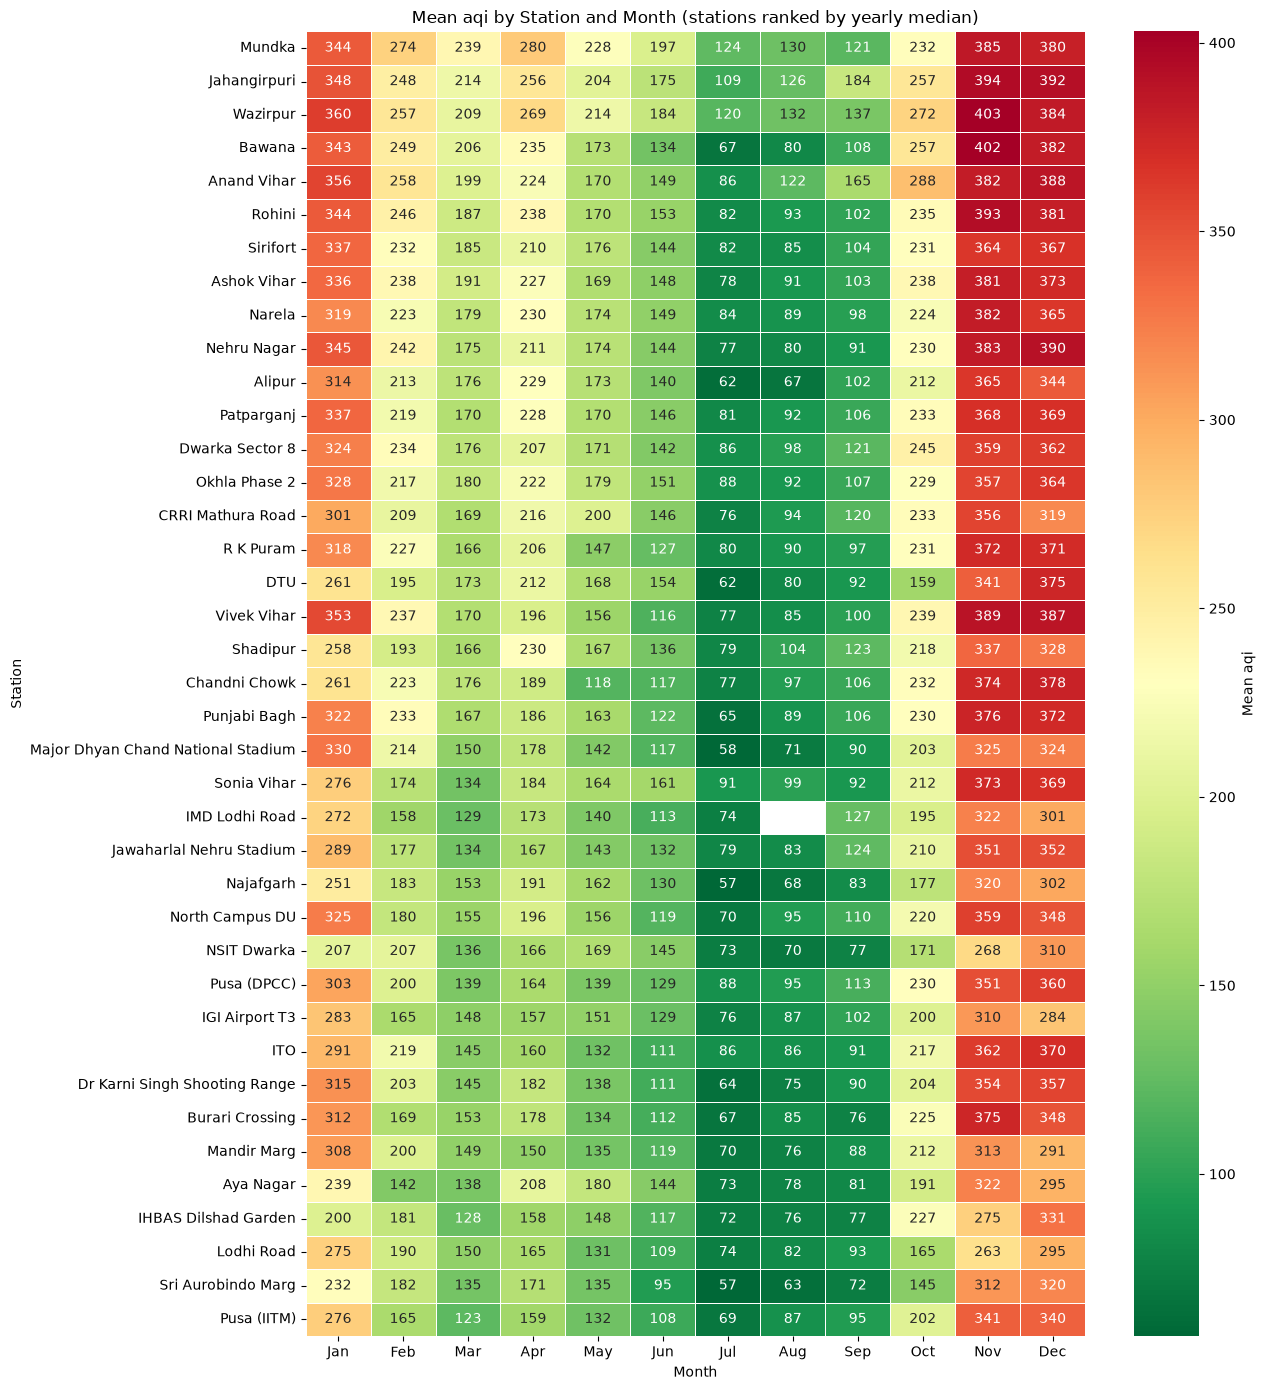

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
station_name,,,,,,,,,,,,
Mundka,344,274,239,280,228,197,124,130,121,232,385,380
Jahangirpuri,348,248,214,256,204,175,109,126,184,257,394,392
Wazirpur,360,257,209,269,214,184,120,132,137,272,403,384
Bawana,343,249,206,235,173,134,67,80,108,257,402,382
Anand Vihar,356,258,199,224,170,149,86,122,165,288,382,388
Rohini,344,246,187,238,170,153,82,93,102,235,393,381
Sirifort,337,232,185,210,176,144,82,85,104,231,364,367
Ashok Vihar,336,238,191,227,169,148,78,91,103,238,381,373
Narela,319,223,179,230,174,149,84,89,98,224,382,365


Saved: station_month_aqi.csv


In [47]:
import calendar
from IPython.display import display

heat = df.pivot_table(index="station_name", columns="month", values="aqi", aggfunc="mean")

# order stations by their yearly median aqi (most polluted at the top)
order = df.groupby("station_name")["aqi"].median().sort_values(ascending=False).index
heat = heat.reindex(order)

# month names instead of numbers
heat.columns = [calendar.month_abbr[m] for m in heat.columns]
heat = heat.round(0)

# 1. Heatmap plot
plt.figure(figsize=(13, 14))
sns.heatmap(heat, annot=True, fmt=".0f", cmap="RdYlGn_r", linewidths=0.5,
            cbar_kws={"label": "Mean aqi"})
plt.title("Mean aqi by Station and Month (stations ranked by yearly median)")
plt.xlabel("Month")
plt.ylabel("Station")
plt.tight_layout()
plt.show()

# 2. The actual data table, coloured green (low) to red (high)
display(heat.style.background_gradient(cmap="RdYlGn_r", axis=None).format("{:.0f}", na_rep="-"))

# 3. Save the table as a CSV file
heat.to_csv("station_month_aqi.csv")
print("Saved: station_month_aqi.csv")

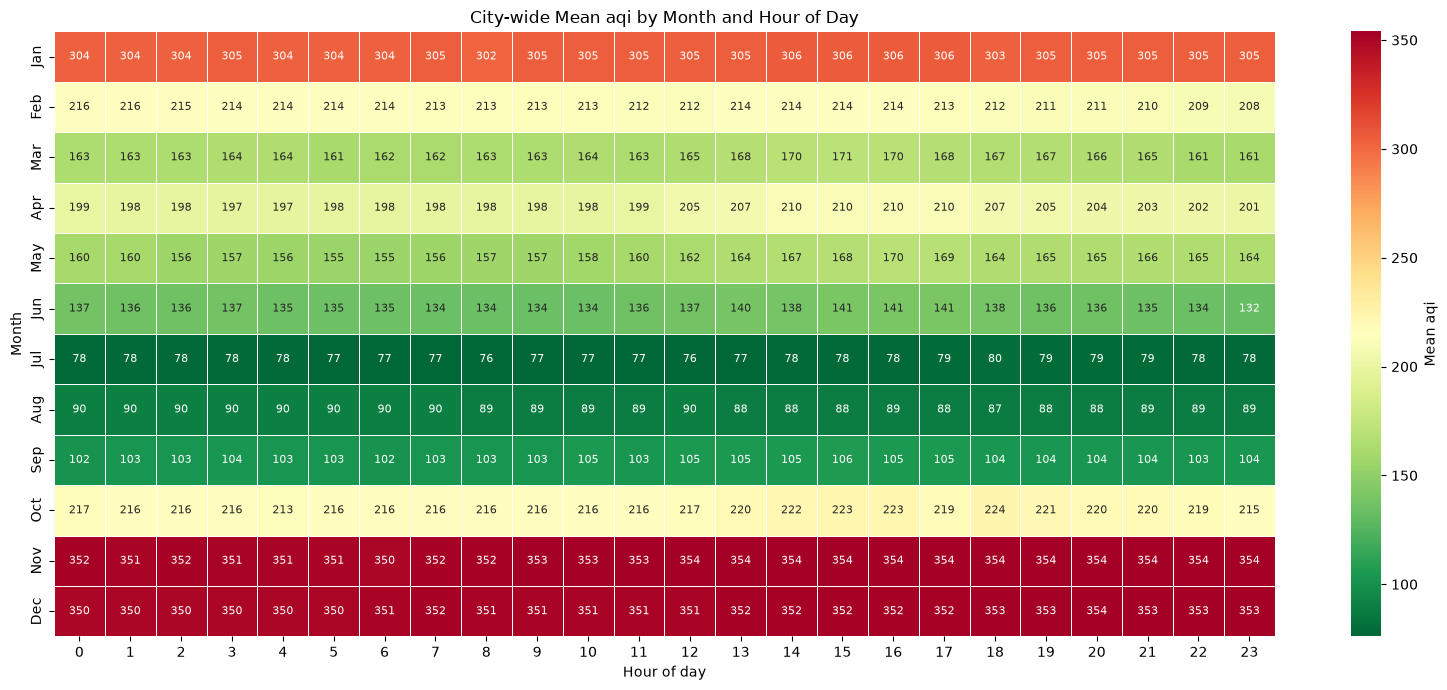

hour     0      1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23
Jan   304.0  304.0  304.0  305.0  304.0  304.0  304.0  305.0  302.0  305.0  305.0  305.0  305.0  305.0  306.0  306.0  306.0  306.0  303.0  305.0  305.0  305.0  305.0  305.0
Feb   216.0  216.0  215.0  214.0  214.0  214.0  214.0  213.0  213.0  213.0  213.0  212.0  212.0  214.0  214.0  214.0  214.0  213.0  212.0  211.0  211.0  210.0  209.0  208.0
Mar   163.0  163.0  163.0  164.0  164.0  161.0  162.0  162.0  163.0  163.0  164.0  163.0  165.0  168.0  170.0  171.0  170.0  168.0  167.0  167.0  166.0  165.0  161.0  161.0
Apr   199.0  198.0  198.0  197.0  197.0  198.0  198.0  198.0  198.0  198.0  198.0  199.0  205.0  207.0  210.0  210.0  210.0  210.0  207.0  205.0  204.0  203.0  202.0  201.0
May   160.0  160.0  156.0  157.0  156.0  155.0  155.0  156.0  157.0  157.0  158.0  160.0  162.0  164.0  167.0  168.0  170.0  169.0  164

In [48]:
city = df.groupby("Timestamp", as_index=False)["aqi"].mean()
city["month"] = city["Timestamp"].dt.month
city["hour"] = city["Timestamp"].dt.hour

heat2 = city.pivot_table(index="month", columns="hour", values="aqi", aggfunc="mean")
heat2.index = [calendar.month_abbr[m] for m in heat2.index]
heat2 = heat2.round(0)

plt.figure(figsize=(16, 7))
sns.heatmap(heat2, annot=True, fmt=".0f", cmap="RdYlGn_r", linewidths=0.5,
            annot_kws={"size": 8}, cbar_kws={"label": "Mean aqi"})
plt.title("City-wide Mean aqi by Month and Hour of Day")
plt.xlabel("Hour of day")
plt.ylabel("Month")
plt.tight_layout()
plt.show()

print(heat2)

heat2.to_csv("month_hour_aqi.csv")
print("Saved: month_hour_aqi.csv")

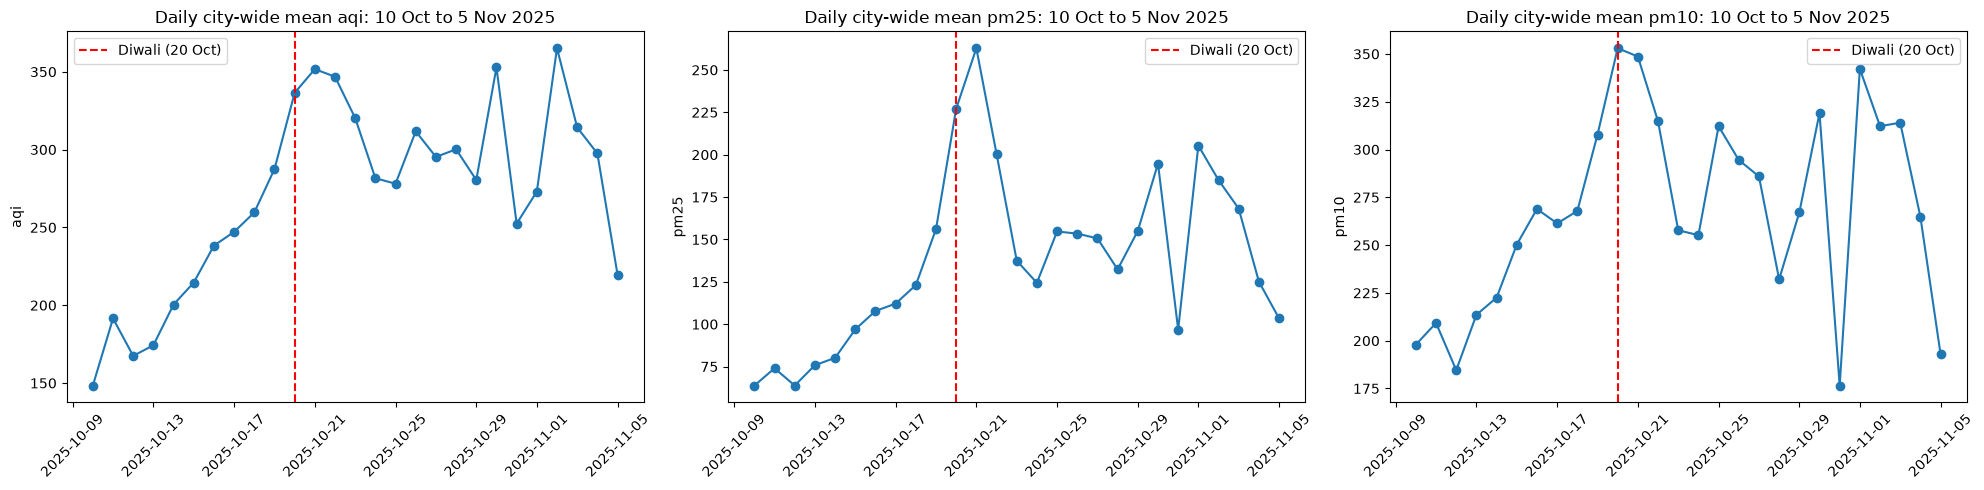

              aqi   pm25   pm10
date                           
2025-10-17  247.0  112.0  261.0
2025-10-18  260.0  123.0  268.0
2025-10-19  287.0  156.0  308.0
2025-10-20  336.0  227.0  353.0
2025-10-21  352.0  263.0  349.0
2025-10-22  347.0  201.0  315.0
2025-10-23  320.0  137.0  258.0
2025-10-24  282.0  124.0  255.0


In [50]:
df["date"] = df["Timestamp"].dt.normalize()
daily = df.groupby("date")[["aqi", "pm25", "pm10"]].mean()
window = daily.loc["2025-10-10":"2025-11-05"]
diwali = pd.Timestamp("2025-10-20")

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, col in zip(axes, ["aqi", "pm25", "pm10"]):
    ax.plot(window.index, window[col], marker="o")
    ax.axvline(diwali, color="red", linestyle="--", label="Diwali (20 Oct)")
    ax.set_title(f"Daily city-wide mean {col}: 10 Oct to 5 Nov 2025")
    ax.set_ylabel(col)
    ax.tick_params(axis="x", rotation=45)
    ax.legend()
plt.tight_layout()
plt.show()

print(window.loc["2025-10-17":"2025-10-24"].round(0))

      aqi  pm25  pm10
Jan  16.9   5.0   4.9
Feb   8.2   4.4   3.9
Mar   5.6   3.1   3.2
Apr   9.7   3.4   3.8
May   6.8   5.5   6.6
Jun   9.3   7.1   6.8
Jul   8.7   9.1   9.8
Aug   9.3   8.5   8.2
Sep   9.7   9.3   9.0
Oct   4.4   3.9   4.2
Nov   1.8   2.0   1.7
Dec   2.2   2.7   2.3


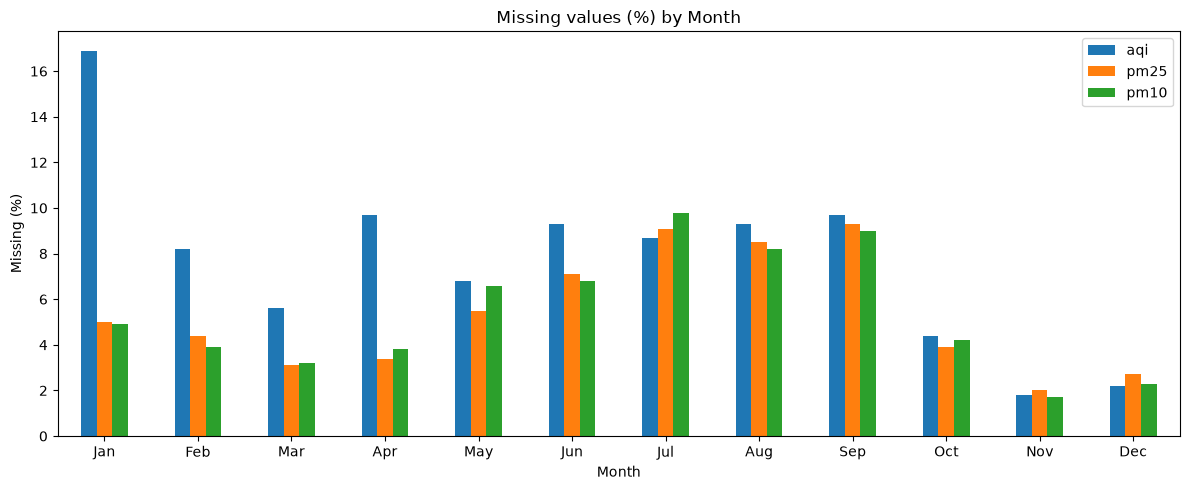

In [51]:
cols = ["aqi", "pm25", "pm10"]
missing = df.groupby("month")[cols].apply(lambda x: x.isna().mean() * 100).round(1)
missing.index = [calendar.month_abbr[m] for m in missing.index]
print(missing)

missing.plot(kind="bar", figsize=(12, 5), rot=0)
plt.title("Missing values (%) by Month")
plt.ylabel("Missing (%)")
plt.xlabel("Month")
plt.tight_layout()
plt.show()

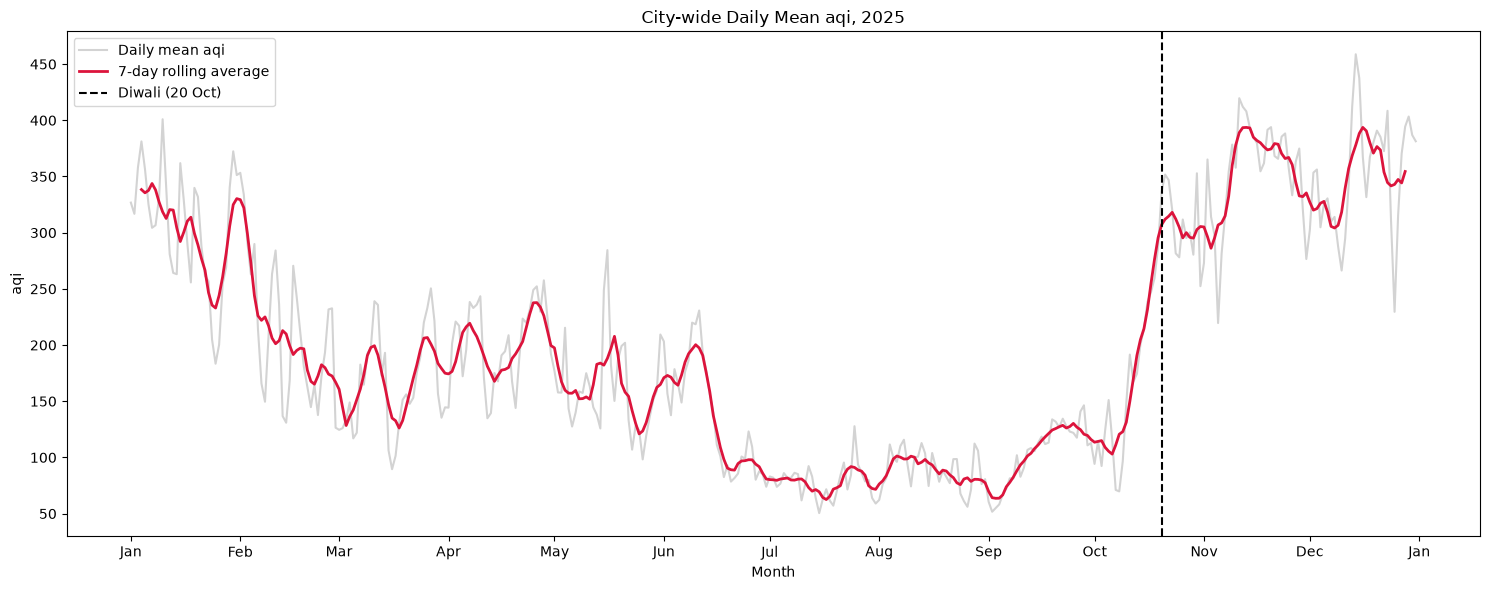

Highest day: 2025-12-14 459
Lowest day: 2025-07-15 50
Days with daily mean aqi above 300: 79
Days with daily mean aqi below 100: 78


In [52]:
import matplotlib.dates as mdates

df["date"] = df["Timestamp"].dt.normalize()
daily_aqi = df.groupby("date")["aqi"].mean()
rolling = daily_aqi.rolling(7, center=True).mean()

plt.figure(figsize=(15, 6))
plt.plot(daily_aqi.index, daily_aqi.values, color="lightgray", label="Daily mean aqi")
plt.plot(rolling.index, rolling.values, color="crimson", linewidth=2, label="7-day rolling average")
plt.axvline(pd.Timestamp("2025-10-20"), color="black", linestyle="--", label="Diwali (20 Oct)")
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%b"))
plt.title("City-wide Daily Mean aqi, 2025")
plt.xlabel("Month")
plt.ylabel("aqi")
plt.legend()
plt.tight_layout()
plt.show()

print("Highest day:", daily_aqi.idxmax().date(), round(daily_aqi.max()))
print("Lowest day:", daily_aqi.idxmin().date(), round(daily_aqi.min()))
print("Days with daily mean aqi above 300:", (daily_aqi > 300).sum())
print("Days with daily mean aqi below 100:", (daily_aqi < 100).sum())

hour     0      1      2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23
pm25  115.0  114.0  110.0  109.0  107.0  106.0  105.0  106.0  109.0  108.0  104.0   96.0   87.0   79.0   73.0   69.0   66.0   67.0   72.0   84.0   96.0  107.0  113.0  115.0
pm10  231.0  223.0  211.0  201.0  194.0  189.0  189.0  196.0  208.0  214.0  211.0  200.0  186.0  175.0  163.0  155.0  152.0  156.0  174.0  200.0  222.0  237.0  240.0  236.0


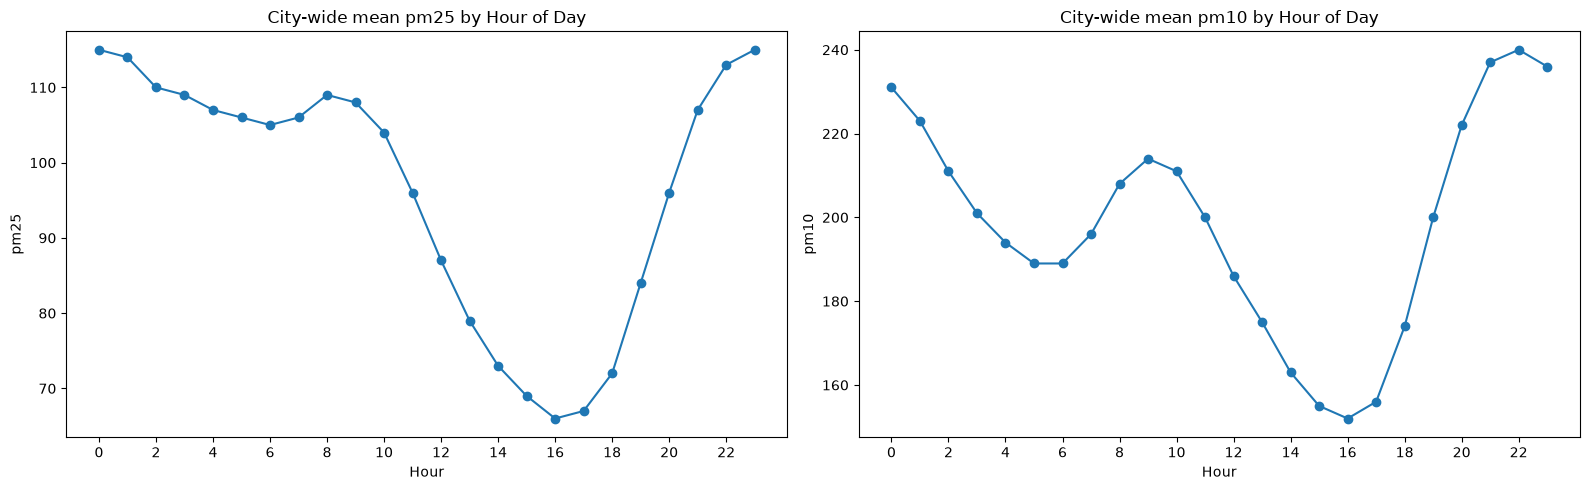

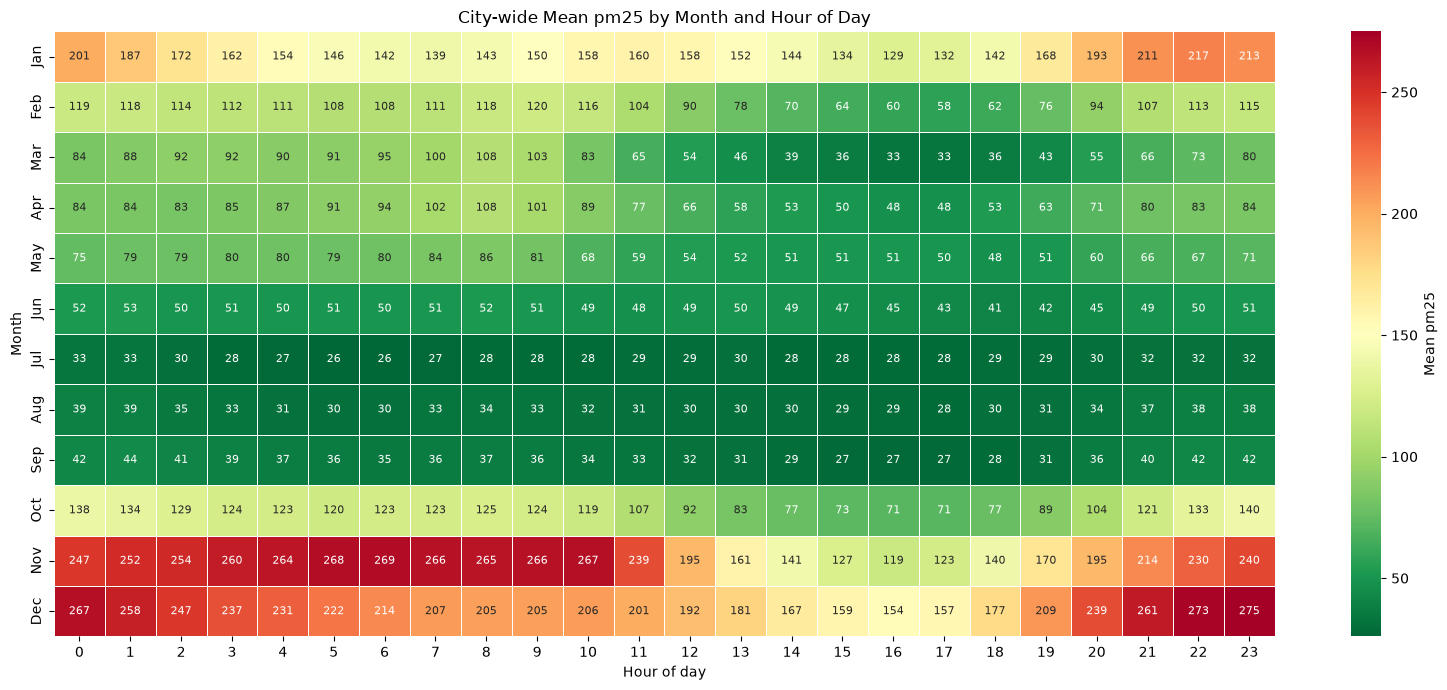

In [53]:
city_pm = df.groupby("Timestamp", as_index=False)[["pm25", "pm10"]].mean()
city_pm["hour"] = city_pm["Timestamp"].dt.hour
city_pm["month"] = city_pm["Timestamp"].dt.month

hourly_pm = city_pm.groupby("hour")[["pm25", "pm10"]].mean().round(0)
print(hourly_pm.T)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, col in zip(axes, ["pm25", "pm10"]):
    ax.plot(hourly_pm.index, hourly_pm[col], marker="o")
    ax.set_xticks(range(0, 24, 2))
    ax.set_title(f"City-wide mean {col} by Hour of Day")
    ax.set_xlabel("Hour")
    ax.set_ylabel(col)
plt.tight_layout()
plt.show()

heat_pm = city_pm.pivot_table(index="month", columns="hour", values="pm25", aggfunc="mean")
heat_pm.index = [calendar.month_abbr[m] for m in heat_pm.index]
plt.figure(figsize=(16, 7))
sns.heatmap(heat_pm.round(0), annot=True, fmt=".0f", cmap="RdYlGn_r", linewidths=0.5,
            annot_kws={"size": 8}, cbar_kws={"label": "Mean pm25"})
plt.title("City-wide Mean pm25 by Month and Hour of Day")
plt.xlabel("Hour of day")
plt.ylabel("Month")
plt.tight_layout()
plt.show()


Streaks of consecutive days with daily mean aqi above 300: 13 episodes
        start         end  days  mean_aqi
0  2025-11-07  2025-11-29    23       372
1  2025-12-12  2025-12-24    13       382
2  2025-01-01  2025-01-11    11       341
3  2025-12-01  2025-12-08     8       325
4  2025-12-26  2025-12-31     6       375

Streaks of consecutive days with daily mean aqi above 200: 17 episodes
        start         end  days  mean_aqi
0  2025-10-14  2025-12-31    79       337
1  2025-01-01  2025-01-24    24       312
2  2025-01-26  2025-02-06    12       295
3  2025-04-22  2025-04-29     8       236
4  2025-02-09  2025-02-12     4       248


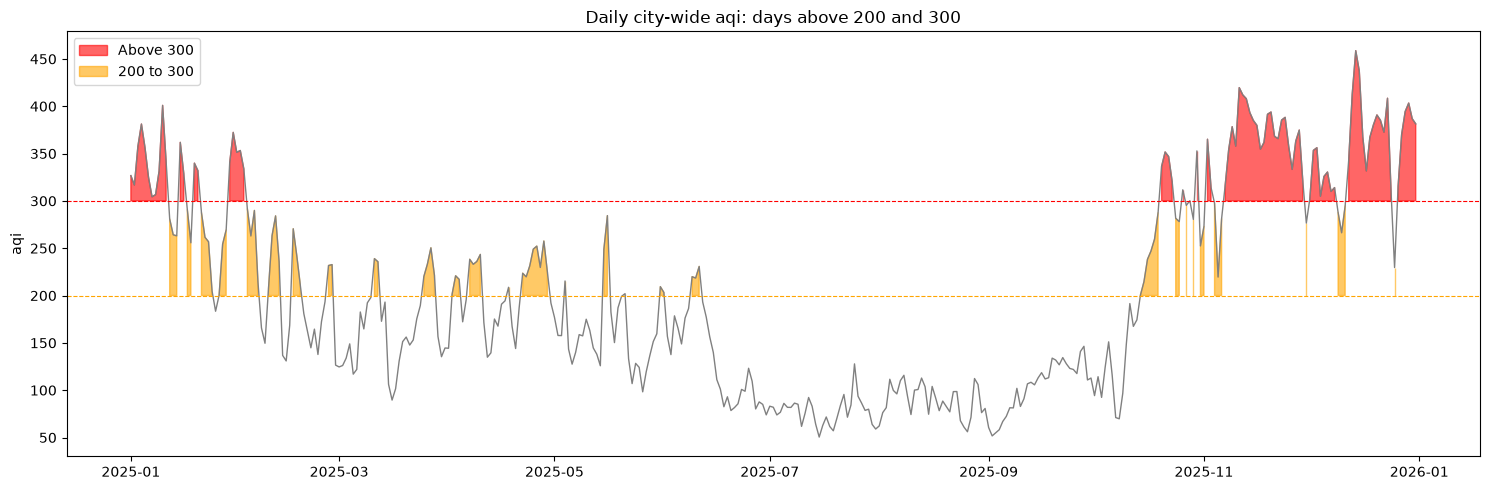

In [54]:
df["date"] = df["Timestamp"].dt.normalize()
daily_aqi = df.groupby("date")["aqi"].mean()

def find_streaks(series, threshold):
    above = series > threshold
    group_id = (above != above.shift()).cumsum()
    rows = []
    for _, chunk in series[above].groupby(group_id[above]):
        rows.append({"start": chunk.index[0].date(), "end": chunk.index[-1].date(),
                     "days": len(chunk), "mean_aqi": round(chunk.mean())})
    return pd.DataFrame(rows).sort_values("days", ascending=False).reset_index(drop=True)

for threshold in [300, 200]:
    streaks = find_streaks(daily_aqi, threshold)
    print(f"\nStreaks of consecutive days with daily mean aqi above {threshold}: {len(streaks)} episodes")
    print(streaks.head(5))

plt.figure(figsize=(15, 5))
plt.plot(daily_aqi.index, daily_aqi.values, color="gray", linewidth=1)
plt.fill_between(daily_aqi.index, daily_aqi.values, 300, where=daily_aqi.values > 300,
                 color="red", alpha=0.6, label="Above 300")
plt.fill_between(daily_aqi.index, daily_aqi.values, 200,
                 where=(daily_aqi.values > 200) & (daily_aqi.values <= 300),
                 color="orange", alpha=0.6, label="200 to 300")
plt.axhline(300, color="red", linestyle="--", linewidth=0.8)
plt.axhline(200, color="orange", linestyle="--", linewidth=0.8)
plt.title("Daily city-wide aqi: days above 200 and 300")
plt.ylabel("aqi")
plt.legend()
plt.tight_layout()
plt.show()

Rows used: 212725
Pearson : -0.57
Spearman: -0.53
            count   mean  median
temp_range                      
(0, 10]       734  337.8   353.0
(10, 15]    26051  325.0   343.0
(15, 20]    31964  288.6   307.0
(20, 25]    31584  238.7   232.0
(25, 30]    62060  149.9   122.0
(30, 35]    49007  142.8   126.0
(35, 50]    11325  183.3   179.0


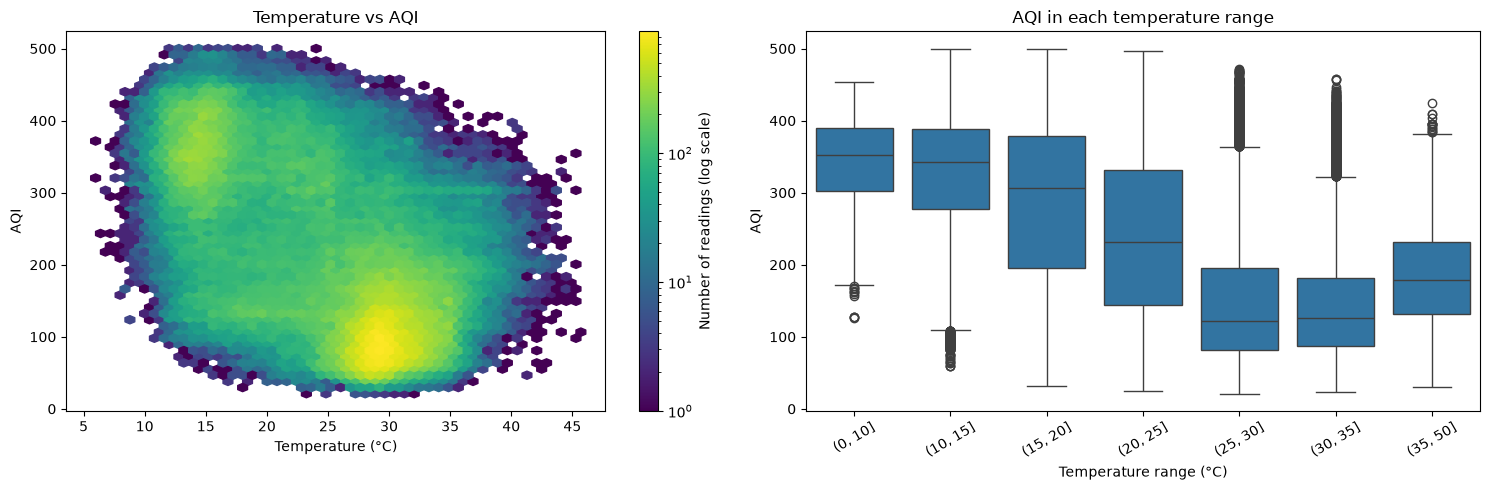

In [55]:


# ---------- SECTION 1: keep only rows where both columns exist ----------
# columns: temperature, aqi -> drop rows where either one is missing
temp_aqi = df[["temperature", "aqi"]].dropna()
print("Rows used:", len(temp_aqi))

# ---------- SECTION 2: correlation (one number) ----------
# columns: temperature vs aqi -> Pearson (straight-line) and Spearman (rank-based)
print("Pearson :", round(temp_aqi["temperature"].corr(temp_aqi["aqi"], method="pearson"), 2))
print("Spearman:", round(temp_aqi["temperature"].corr(temp_aqi["aqi"], method="spearman"), 2))

# ---------- SECTION 3: group temperature into ranges ----------
# column: temperature -> cut into ranges (bins); then look at aqi inside each range
temp_aqi["temp_range"] = pd.cut(temp_aqi["temperature"], bins=[0, 10, 15, 20, 25, 30, 35, 50])
print(temp_aqi.groupby("temp_range", observed=True)["aqi"].agg(["count", "mean", "median"]).round(1))

# ---------- SECTION 4: plots (hexbin + boxplot side by side) ----------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# columns: temperature (x) vs aqi (y) -> hexbin, because 212k points would be a solid blob in a normal scatter
hb = axes[0].hexbin(temp_aqi["temperature"], temp_aqi["aqi"], gridsize=50, cmap="viridis", mincnt=1, bins="log")
fig.colorbar(hb, ax=axes[0], label="Number of readings (log scale)")
axes[0].set_xlabel("Temperature (°C)")
axes[0].set_ylabel("AQI")
axes[0].set_title("Temperature vs AQI")

# columns: temp_range (x) vs aqi (y) -> boxplot of aqi inside each temperature range
sns.boxplot(data=temp_aqi, x="temp_range", y="aqi", ax=axes[1])
axes[1].set_xlabel("Temperature range (°C)")
axes[1].set_ylabel("AQI")
axes[1].set_title("AQI in each temperature range")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Rows used: 247662
Pearson : -0.03
Spearman: -0.1
           count   mean  median
hum_range                      
(0, 20]     1436  189.7   184.0
(20, 40]   27244  218.9   209.0
(40, 60]   69762  206.8   183.0
(60, 80]   78843  186.5   146.0
(80, 100]  70377  206.2   162.0
Winter | rows: 59934 | avg humidity: 71.9 | avg aqi: 297.2 | correlation: 0.3
Summer | rows: 63621 | avg humidity: 50.0 | avg aqi: 179.7 | correlation: -0.26
Monsoon | rows: 82309 | avg humidity: 71.7 | avg aqi: 103.6 | correlation: -0.5
Post-monsoon | rows: 41798 | avg humidity: 67.5 | avg aqi: 289.6 | correlation: -0.21


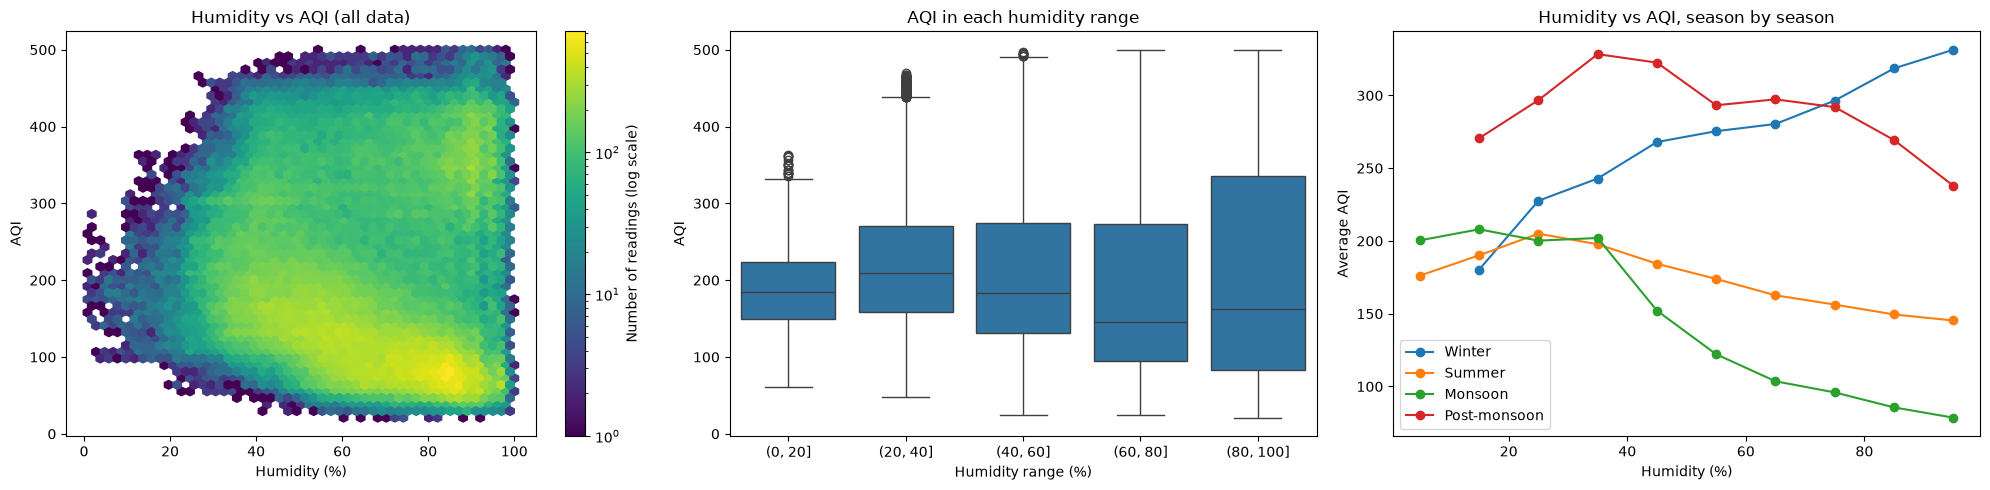

In [56]:


# ---------- SECTION 1: keep only rows where both columns exist ----------
# columns: humidity, aqi -> drop rows where either one is missing
hum_aqi = df[["humidity", "aqi", "Timestamp"]].dropna(subset=["humidity", "aqi"]).copy()
print("Rows used:", len(hum_aqi))

# ---------- SECTION 2: overall correlation ----------
# columns: humidity vs aqi -> Pearson (straight-line) and Spearman (rank-based)
print("Pearson :", round(hum_aqi["humidity"].corr(hum_aqi["aqi"], method="pearson"), 2))
print("Spearman:", round(hum_aqi["humidity"].corr(hum_aqi["aqi"], method="spearman"), 2))

# ---------- SECTION 3: humidity ranges ----------
# column: humidity -> cut into ranges; then look at aqi inside each range
hum_aqi["hum_range"] = pd.cut(hum_aqi["humidity"], bins=[0, 20, 40, 60, 80, 100])
print(hum_aqi.groupby("hum_range", observed=True)["aqi"].agg(["count", "mean", "median"]).round(1))

# ---------- SECTION 4: add season (from Timestamp) ----------
# column: Timestamp -> take the month, then map each month to a season
def get_season(month):
    if month in (12, 1, 2):
        return "Winter"
    elif month in (3, 4, 5):
        return "Summer"
    elif month in (6, 7, 8, 9):
        return "Monsoon"
    else:
        return "Post-monsoon"

hum_aqi["season"] = hum_aqi["Timestamp"].dt.month.map(get_season)

# ---------- SECTION 5: correlation and averages inside each season ----------
# columns: humidity vs aqi -> correlation calculated separately for each season
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
for s in season_order:
    part = hum_aqi[hum_aqi["season"] == s]
    print(s, "| rows:", len(part),
          "| avg humidity:", round(part["humidity"].mean(), 1),
          "| avg aqi:", round(part["aqi"].mean(), 1),
          "| correlation:", round(part["humidity"].corr(part["aqi"]), 2))

# ---------- SECTION 6: plots ----------
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# columns: humidity (x) vs aqi (y) -> hexbin for all rows together
hb = axes[0].hexbin(hum_aqi["humidity"], hum_aqi["aqi"], gridsize=50, cmap="viridis", mincnt=1, bins="log")
fig.colorbar(hb, ax=axes[0], label="Number of readings (log scale)")
axes[0].set_xlabel("Humidity (%)")
axes[0].set_ylabel("AQI")
axes[0].set_title("Humidity vs AQI (all data)")

# columns: hum_range (x) vs aqi (y) -> boxplot of aqi inside each humidity range
sns.boxplot(data=hum_aqi, x="hum_range", y="aqi", ax=axes[1])
axes[1].set_xlabel("Humidity range (%)")
axes[1].set_ylabel("AQI")
axes[1].set_title("AQI in each humidity range")

# columns: humidity (x) vs aqi (y) -> mean aqi per humidity range, one line per season
hum_aqi["hum_range_10"] = pd.cut(hum_aqi["humidity"], bins=range(0, 101, 10))
line_data = (hum_aqi.groupby(["season", "hum_range_10"], observed=True)["aqi"]
             .mean().reset_index())
line_data["hum_mid"] = line_data["hum_range_10"].apply(lambda r: r.mid)
for s in season_order:
    part = line_data[line_data["season"] == s]
    axes[2].plot(part["hum_mid"], part["aqi"], marker="o", label=s)
axes[2].set_xlabel("Humidity (%)")
axes[2].set_ylabel("Average AQI")
axes[2].set_title("Humidity vs AQI, season by season")
axes[2].legend()

plt.tight_layout()
plt.show()

Rows used: 232608
count    232608.00
mean          1.13
std           1.01
min           0.01
25%           0.38
50%           0.82
75%           1.50
max          14.92
Name: wind_speed, dtype: float64
Pearson : -0.17
Spearman: -0.18
              count   mean  median
wind_range                        
(-0.01, 0.5]  77849  228.6   216.0
(0.5, 1.0]    54991  198.9   171.0
(1.0, 1.5]    42275  188.2   161.0
(1.5, 2.0]    24001  182.8   154.0
(2.0, 3.0]    20405  178.6   153.0
(3.0, 20.0]   13087  157.3   140.0
Winter | rows: 56975 | avg wind: 0.96 | avg aqi: 298.0 | correlation: -0.12
Summer | rows: 60869 | avg wind: 1.36 | avg aqi: 179.2 | correlation: -0.01
Monsoon | rows: 77136 | avg wind: 1.28 | avg aqi: 104.4 | correlation: 0.01
Post-monsoon | rows: 37628 | avg wind: 0.72 | avg aqi: 288.2 | correlation: -0.07


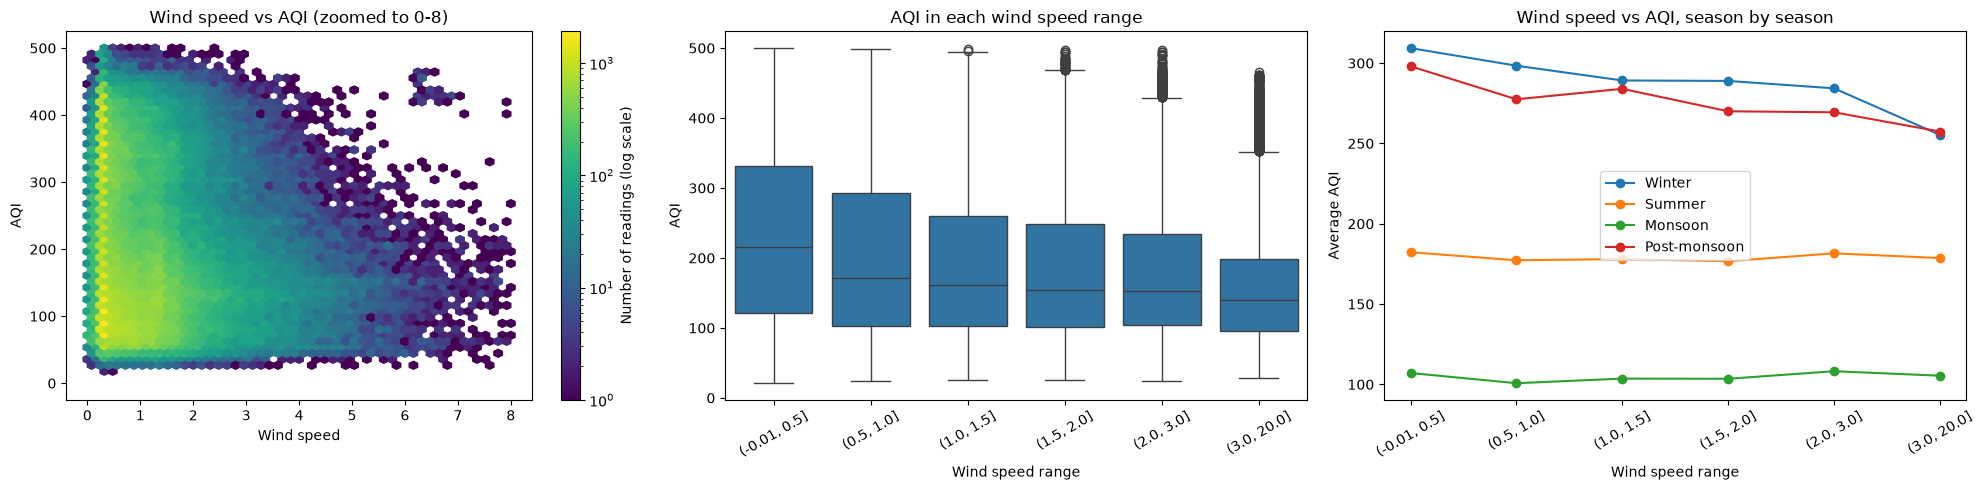

In [63]:

# ---------- SECTION 1: keep only rows where both columns exist ----------
# columns: wind_speed, aqi -> drop rows where either one is missing
wind_aqi = df[["wind_speed", "aqi", "Timestamp"]].dropna().copy()
print("Rows used:", len(wind_aqi))

# ---------- SECTION 2: how wind_speed itself behaves ----------
# column: wind_speed -> most values are small, a few are very high
print(wind_aqi["wind_speed"].describe().round(2))

# ---------- SECTION 3: overall correlation ----------
# columns: wind_speed vs aqi -> Pearson (straight-line) and Spearman (rank-based)
print("Pearson :", round(wind_aqi["wind_speed"].corr(wind_aqi["aqi"], method="pearson"), 2))
print("Spearman:", round(wind_aqi["wind_speed"].corr(wind_aqi["aqi"], method="spearman"), 2))

# ---------- SECTION 4: wind_speed ranges ----------
# column: wind_speed -> cut into ranges; then look at aqi inside each range
wind_aqi["wind_range"] = pd.cut(wind_aqi["wind_speed"], bins=[-0.01, 0.5, 1, 1.5, 2, 3, 20])
print(wind_aqi.groupby("wind_range", observed=True)["aqi"].agg(["count", "mean", "median"]).round(1))

# ---------- SECTION 5: add season (from Timestamp) ----------
# column: Timestamp -> take the month, then map each month to a season
def get_season(month):
    if month in (12, 1, 2):
        return "Winter"
    elif month in (3, 4, 5):
        return "Summer"
    elif month in (6, 7, 8, 9):
        return "Monsoon"
    else:
        return "Post-monsoon"

wind_aqi["season"] = wind_aqi["Timestamp"].dt.month.map(get_season)

# ---------- SECTION 6: correlation and averages inside each season ----------
# columns: wind_speed vs aqi -> correlation calculated separately for each season
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
for s in season_order:
    part = wind_aqi[wind_aqi["season"] == s]
    print(s, "| rows:", len(part),
          "| avg wind:", round(part["wind_speed"].mean(), 2),
          "| avg aqi:", round(part["aqi"].mean(), 1),
          "| correlation:", round(part["wind_speed"].corr(part["aqi"]), 2))

# ---------- SECTION 7: plots ----------
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# columns: wind_speed (x) vs aqi (y) -> hexbin for all rows together
hb = axes[0].hexbin(wind_aqi["wind_speed"], wind_aqi["aqi"], gridsize=50, cmap="viridis",
                    mincnt=1, bins="log", extent=(0, 8, 0, 500))
fig.colorbar(hb, ax=axes[0], label="Number of readings (log scale)")
axes[0].set_xlabel("Wind speed")
axes[0].set_ylabel("AQI")
axes[0].set_title("Wind speed vs AQI (zoomed to 0-8)")

# columns: wind_range (x) vs aqi (y) -> boxplot of aqi inside each wind range
sns.boxplot(data=wind_aqi, x="wind_range", y="aqi", ax=axes[1])
axes[1].set_xlabel("Wind speed range")
axes[1].set_ylabel("AQI")
axes[1].set_title("AQI in each wind speed range")
axes[1].tick_params(axis="x", rotation=30)

# columns: wind_speed (x) vs aqi (y) -> mean aqi per wind range, one line per season
line_data = (wind_aqi.groupby(["season", "wind_range"], observed=True)["aqi"]
             .mean().reset_index())
for s in season_order:
    part = line_data[line_data["season"] == s]
    axes[2].plot(part["wind_range"].astype(str), part["aqi"], marker="o", label=s)
axes[2].set_xlabel("Wind speed range")
axes[2].set_ylabel("Average AQI")
axes[2].set_title("Wind speed vs AQI, season by season")
axes[2].tick_params(axis="x", rotation=30)
axes[2].legend()

plt.tight_layout()
plt.show()

Rows used: 239837
direction
N      4.4
NE     6.7
E     11.3
SE    17.0
S     21.2
SW    18.1
W     13.2
NW     8.0
Name: proportion, dtype: float64
           count   mean  median
direction                      
N          10602  213.1   188.0
NE         16124  219.2   203.0
E          27091  194.4   166.0
SE         40890  184.4   154.0
S          50816  195.4   167.0
SW         43399  206.0   178.0
W          31623  203.5   178.0
NW         19292  212.9   191.0
direction
N     171.7
NE    217.9
E     177.1
SE    159.6
S     173.0
SW    182.2
W     193.4
NW    208.6
Name: aqi, dtype: float64
season     Winter  Summer  Monsoon  Post-monsoon
direction                                       
N           312.0   176.0     98.0         305.0
NE          303.0   189.0    106.0         280.0
E           299.0   185.0    104.0         271.0
SE          317.0   179.0    102.0         289.0
S           306.0   176.0    102.0         295.0
SW          298.0   178.0    103.0         295.0
W      

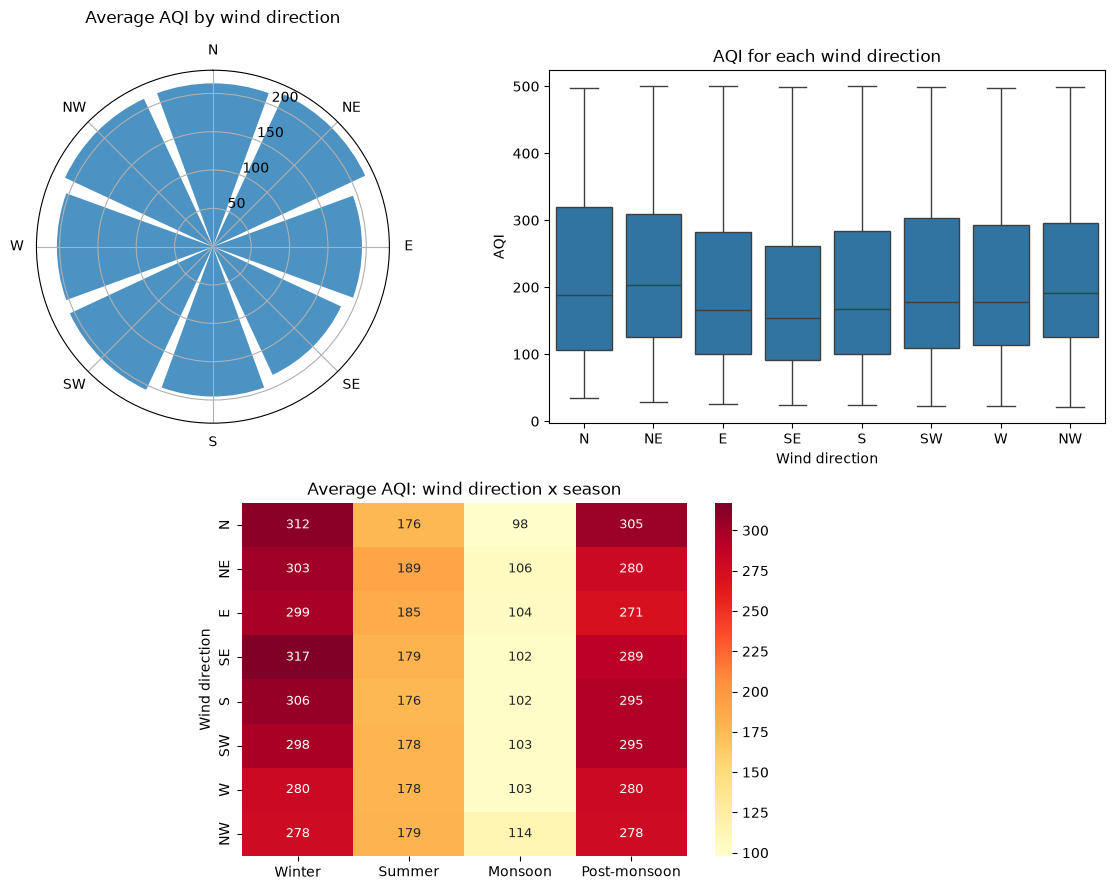

In [64]:


# ---------- SECTION 1: keep only rows where both columns exist ----------
# columns: wind_direction, aqi -> drop rows where either one is missing
# (wind_speed is kept as it is, it can stay missing, we only use it in Section 5)
wd_aqi = df[["wind_direction", "wind_speed", "aqi", "Timestamp"]].dropna(subset=["wind_direction", "aqi"]).copy()
print("Rows used:", len(wd_aqi))

# ---------- SECTION 2: turn degrees into 8 compass directions ----------
# column: wind_direction -> each direction covers 45 degrees (N is 337.5 to 22.5)
compass = ["N", "NE", "E", "SE", "S", "SW", "W", "NW"]

def to_compass(degree):
    index = int(((degree + 22.5) % 360) // 45)
    return compass[index]

wd_aqi["direction"] = wd_aqi["wind_direction"].map(to_compass)
wd_aqi["direction"] = pd.Categorical(wd_aqi["direction"], categories=compass, ordered=True)

# ---------- SECTION 3: how often wind comes from each direction ----------
# column: direction -> share of readings (%) for each direction
print((wd_aqi["direction"].value_counts(normalize=True).reindex(compass) * 100).round(1))

# ---------- SECTION 4: aqi for each direction ----------
# columns: direction vs aqi -> count, mean and median
print(wd_aqi.groupby("direction", observed=True)["aqi"].agg(["count", "mean", "median"]).round(1))

# ---------- SECTION 5: only reliable wind (wind_speed 1 or more) ----------
# columns: wind_speed, direction, aqi -> when wind is almost calm, the direction reading is not meaningful
strong = wd_aqi[wd_aqi["wind_speed"] >= 1]
strong_mean = strong.groupby("direction", observed=True)["aqi"].mean().round(1)
print(strong_mean)

# ---------- SECTION 6: add season (from Timestamp) ----------
# column: Timestamp -> take the month, then map each month to a season
def get_season(month):
    if month in (12, 1, 2):
        return "Winter"
    elif month in (3, 4, 5):
        return "Summer"
    elif month in (6, 7, 8, 9):
        return "Monsoon"
    else:
        return "Post-monsoon"

wd_aqi["season"] = wd_aqi["Timestamp"].dt.month.map(get_season)

# columns: direction vs aqi -> average aqi for each direction inside each season
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
season_table = wd_aqi.pivot_table(index="direction", columns="season", values="aqi",
                                  aggfunc="mean", observed=True)[season_order].round(0)
print(season_table)

# ---------- SECTION 7: plots (each graph is its own figure, medium size) ----------
# ---------- SECTION 7: plots (2 graphs on top, 1 graph below) ----------
fig = plt.figure(figsize=(12, 9))
grid = fig.add_gridspec(2, 4)   # 2 rows, 4 columns: top row = 2 graphs, bottom row = 1 graph in the middle

# GRAPH 1 (top left): wind-rose style circle
# columns: direction vs aqi
# What it shows: the circle is like a compass. Each bar points to the direction the wind comes FROM,
# and a longer bar means a higher average aqi from that direction.
# Look for: the longest bars (worst air) and the shortest bars (best air).
mean_aqi = wd_aqi.groupby("direction", observed=True)["aqi"].mean().reindex(compass)
angles = np.deg2rad(np.arange(0, 360, 45))

ax1 = fig.add_subplot(grid[0, 0:2], projection="polar")
ax1.bar(angles, mean_aqi.values, width=np.deg2rad(40), alpha=0.8)
ax1.set_theta_zero_location("N")
ax1.set_theta_direction(-1)
ax1.set_xticks(angles)
ax1.set_xticklabels(compass, fontsize=10)
ax1.set_title("Average AQI by wind direction", fontsize=12, pad=15)

# GRAPH 2 (top right): boxplot
# columns: direction vs aqi
# What it shows: the full spread of aqi for each direction, not only the average.
# The line inside each box is the median, the box is the middle 50% of readings,
# and the dots above are very high readings.
# Look for: boxes that sit higher (worse air) and how much the boxes overlap.
# If they overlap a lot, direction alone is a weak factor.
ax2 = fig.add_subplot(grid[0, 2:4])
sns.boxplot(data=wd_aqi, x="direction", y="aqi", ax=ax2)
ax2.set_xlabel("Wind direction", fontsize=10)
ax2.set_ylabel("AQI", fontsize=10)
ax2.set_title("AQI for each wind direction", fontsize=12)

# GRAPH 3 (bottom, middle): heatmap
# columns: direction vs season, colour = average aqi
# What it shows: a table turned into colours. Each box is the average aqi for one direction in one season.
# Darker red means worse air.
# Look for: whether the same direction is bad in every season (a column pattern)
# or whether the season matters more than the direction (the colours change left to right).
ax3 = fig.add_subplot(grid[1, 1:3])
sns.heatmap(season_table, annot=True, fmt=".0f", cmap="YlOrRd", annot_kws={"size": 9}, ax=ax3)
ax3.set_title("Average AQI: wind direction x season", fontsize=12)
ax3.set_xlabel("")
ax3.set_ylabel("Wind direction", fontsize=10)

plt.tight_layout()
plt.show()


Rows used: 174439
Hours with zero rain (%): 97.7
Hours with rain: 4012
Pearson : -0.06
Spearman: -0.14
              count   mean  median
rain_status                       
No rain      170427  209.3   183.0
Rain           4012  113.0    94.0
             count   mean  median
rain_range                       
(0.0, 0.1]     242  144.4   123.0
(0.1, 0.5]    2146  116.0    94.0
(0.5, 1.0]     563  102.8    82.0
(1.0, 2.0]     424  104.8    91.5
(2.0, 30.0]    637  105.4    97.0
                          count   mean
season       rain_status              
Monsoon      No rain      54397  106.2
             Rain          3024   87.6
Post-monsoon No rain      29256  297.8
             Rain           188  113.9
Summer       No rain      43295  184.0
             Rain           635  181.0
Winter       No rain      43479  303.8
             Rain           165  315.7


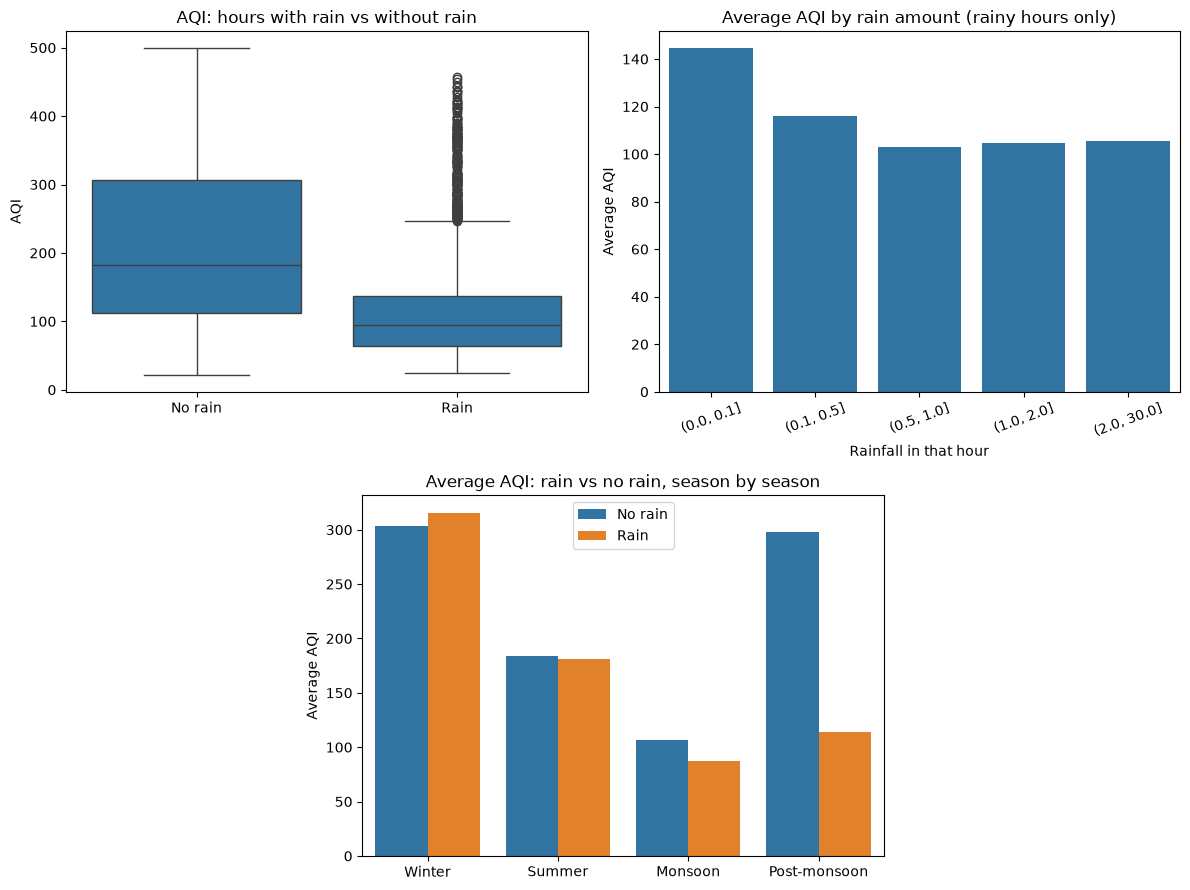

In [65]:


# ---------- SECTION 1: keep only rows where both columns exist ----------
# columns: rainfall, aqi -> drop rows where either one is missing
rain_aqi = df[["rainfall", "aqi", "Timestamp"]].dropna().copy()
print("Rows used:", len(rain_aqi))

# ---------- SECTION 2: how rainfall itself behaves ----------
# column: rainfall -> share of hours with exactly 0 rain, and how many hours had rain
print("Hours with zero rain (%):", round((rain_aqi["rainfall"] == 0).mean() * 100, 1))
print("Hours with rain:", (rain_aqi["rainfall"] > 0).sum())

# ---------- SECTION 3: overall correlation ----------
# columns: rainfall vs aqi -> Pearson (straight-line) and Spearman (rank-based)
print("Pearson :", round(rain_aqi["rainfall"].corr(rain_aqi["aqi"], method="pearson"), 2))
print("Spearman:", round(rain_aqi["rainfall"].corr(rain_aqi["aqi"], method="spearman"), 2))

# ---------- SECTION 4: rain vs no rain ----------
# column: rainfall -> label each hour as "Rain" (more than 0) or "No rain" (exactly 0)
rain_aqi["rain_status"] = np.where(rain_aqi["rainfall"] > 0, "Rain", "No rain")
print(rain_aqi.groupby("rain_status")["aqi"].agg(["count", "mean", "median"]).round(1))

# ---------- SECTION 5: how heavy the rain was (only hours with rain) ----------
# column: rainfall -> cut the rainy hours into ranges; then look at aqi inside each range
rainy = rain_aqi[rain_aqi["rainfall"] > 0].copy()
rainy["rain_range"] = pd.cut(rainy["rainfall"], bins=[0, 0.1, 0.5, 1, 2, 30])
print(rainy.groupby("rain_range", observed=True)["aqi"].agg(["count", "mean", "median"]).round(1))

# ---------- SECTION 6: add season (from Timestamp) ----------
# column: Timestamp -> take the month, then map each month to a season
def get_season(month):
    if month in (12, 1, 2):
        return "Winter"
    elif month in (3, 4, 5):
        return "Summer"
    elif month in (6, 7, 8, 9):
        return "Monsoon"
    else:
        return "Post-monsoon"

rain_aqi["season"] = rain_aqi["Timestamp"].dt.month.map(get_season)

# columns: season, rain_status vs aqi -> count and average aqi, rain vs no rain inside each season
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
print(rain_aqi.groupby(["season", "rain_status"])["aqi"].agg(["count", "mean"]).round(1))

# ---------- SECTION 7: plots (2 graphs on top, 1 graph below) ----------
fig = plt.figure(figsize=(12, 9))
grid = fig.add_gridspec(2, 4)

# GRAPH 1 (top left): rain vs no rain
# columns: rain_status vs aqi
# What it shows: the full spread of aqi in hours with rain and in hours without rain.
# The line inside each box is the median, the box is the middle 50% of readings.
# Look for: is the "Rain" box clearly lower than the "No rain" box?
ax1 = fig.add_subplot(grid[0, 0:2])
sns.boxplot(data=rain_aqi, x="rain_status", y="aqi", order=["No rain", "Rain"], ax=ax1)
ax1.set_xlabel("")
ax1.set_ylabel("AQI", fontsize=10)
ax1.set_title("AQI: hours with rain vs without rain", fontsize=12)

# GRAPH 2 (top right): heavy rain vs light rain
# columns: rain_range vs aqi (only hours with rain)
# What it shows: the average aqi for each rain amount. Each bar is one range of rainfall.
# Look for: does the bar keep going down as the rain gets heavier,
# or does it stop going down after some point?
ax2 = fig.add_subplot(grid[0, 2:4])
sns.barplot(data=rainy, x="rain_range", y="aqi", estimator="mean", errorbar=None, ax=ax2)
ax2.set_xlabel("Rainfall in that hour", fontsize=10)
ax2.set_ylabel("Average AQI", fontsize=10)
ax2.set_title("Average AQI by rain amount (rainy hours only)", fontsize=12)
ax2.tick_params(axis="x", rotation=20)

# GRAPH 3 (bottom, middle): rain vs no rain inside each season
# columns: season, rain_status vs aqi
# What it shows: for each season, two bars: average aqi without rain and with rain.
# Look for: in which season is the rain bar clearly lower than the no-rain bar?
# If the two bars are almost the same, rain made no visible difference there.
ax3 = fig.add_subplot(grid[1, 1:3])
sns.barplot(data=rain_aqi, x="season", y="aqi", hue="rain_status", order=season_order,
            hue_order=["No rain", "Rain"], estimator="mean", errorbar=None, ax=ax3)
ax3.set_xlabel("")
ax3.set_ylabel("Average AQI", fontsize=10)
ax3.set_title("Average AQI: rain vs no rain, season by season", fontsize=12)
ax3.legend(title="")

plt.tight_layout()
plt.show()

Correlation: 0.996
total_rainfall > 0 but rainfall = 0: 0
total_rainfall = 0 but rainfall > 0: 0
count    4194.00
mean        4.00
std         0.26
min         1.00
25%         4.00
50%         4.00
75%         4.02
max         4.17
dtype: float64
Pearson : -0.06
Spearman: -0.14
              count   mean  median
rain_status                       
No rain      170427  209.3   183.0
Rain           4012  113.0    94.0


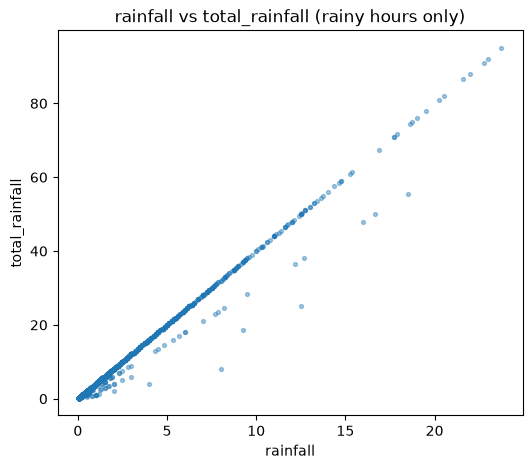

In [67]:


# ---------- SECTION 1: are rainfall and total_rainfall the same information? ----------
# columns: rainfall, total_rainfall -> keep rows where both exist
both = df[["rainfall", "total_rainfall"]].dropna()

# columns: rainfall vs total_rainfall -> correlation close to 1 means they move together exactly
print("Correlation:", round(both["rainfall"].corr(both["total_rainfall"]), 3))

# columns: rainfall, total_rainfall -> is one zero when the other is zero?
print("total_rainfall > 0 but rainfall = 0:", ((both["total_rainfall"] > 0) & (both["rainfall"] == 0)).sum())
print("total_rainfall = 0 but rainfall > 0:", ((both["total_rainfall"] == 0) & (both["rainfall"] > 0)).sum())

# columns: total_rainfall / rainfall -> ratio, only for the rainy hours
rainy_both = both[both["rainfall"] > 0]
print((rainy_both["total_rainfall"] / rainy_both["rainfall"]).describe().round(2))

# ---------- SECTION 2: total_rainfall vs aqi ----------
# columns: total_rainfall, aqi -> keep rows where both exist
tr_aqi = df[["total_rainfall", "aqi"]].dropna().copy()

# columns: total_rainfall vs aqi -> Pearson and Spearman
print("Pearson :", round(tr_aqi["total_rainfall"].corr(tr_aqi["aqi"], method="pearson"), 2))
print("Spearman:", round(tr_aqi["total_rainfall"].corr(tr_aqi["aqi"], method="spearman"), 2))

# column: total_rainfall -> rain (more than 0) vs no rain (exactly 0), then mean aqi
tr_aqi["rain_status"] = np.where(tr_aqi["total_rainfall"] > 0, "Rain", "No rain")
print(tr_aqi.groupby("rain_status")["aqi"].agg(["count", "mean", "median"]).round(1))

# ---------- SECTION 3: plot ----------
# columns: rainfall (x) vs total_rainfall (y), only rainy hours
# What it shows: every dot is one rainy hour. If all dots sit on one straight line,
# then total_rainfall is just rainfall multiplied by a fixed number.
# Look for: a clean straight line with almost no scatter around it.
plt.figure(figsize=(6, 5))
plt.scatter(rainy_both["rainfall"], rainy_both["total_rainfall"], s=8, alpha=0.4)
plt.xlabel("rainfall")
plt.ylabel("total_rainfall")
plt.title("rainfall vs total_rainfall (rainy hours only)")
plt.show()

Rows used: 206458
hour
0       8.0
1       8.0
2       8.0
3       8.0
4       8.0
5      10.0
6      21.0
7      56.0
8     123.0
9     199.0
10    273.0
11    329.0
12    356.0
13    340.0
14    278.0
15    193.0
16    115.0
17     56.0
18     23.0
19     10.0
20      8.0
21      8.0
22      8.0
23      8.0
Name: solar_radiation, dtype: float64
Pearson : -0.1
Spearman: -0.03
             count   mean  median
sun_status                       
No sun       42639  203.5   176.0
Sun is up   163819  204.9   178.0
              count   mean  median
sun_range                         
(5, 100]     100090  212.1   188.0
(100, 200]    20296  204.8   174.0
(200, 400]    28001  202.3   177.0
(400, 600]    12383  164.1   154.0
(600, 1100]    3049  157.1   149.0
Winter | rows: 39265 | avg sun: 93.0 | avg aqi: 305.9 | correlation: -0.15
Summer | rows: 40982 | avg sun: 185.0 | avg aqi: 185.6 | correlation: -0.02
Monsoon | rows: 56117 | avg sun: 136.0 | avg aqi: 105.0 | correlation: 0.08
Post-monsoon

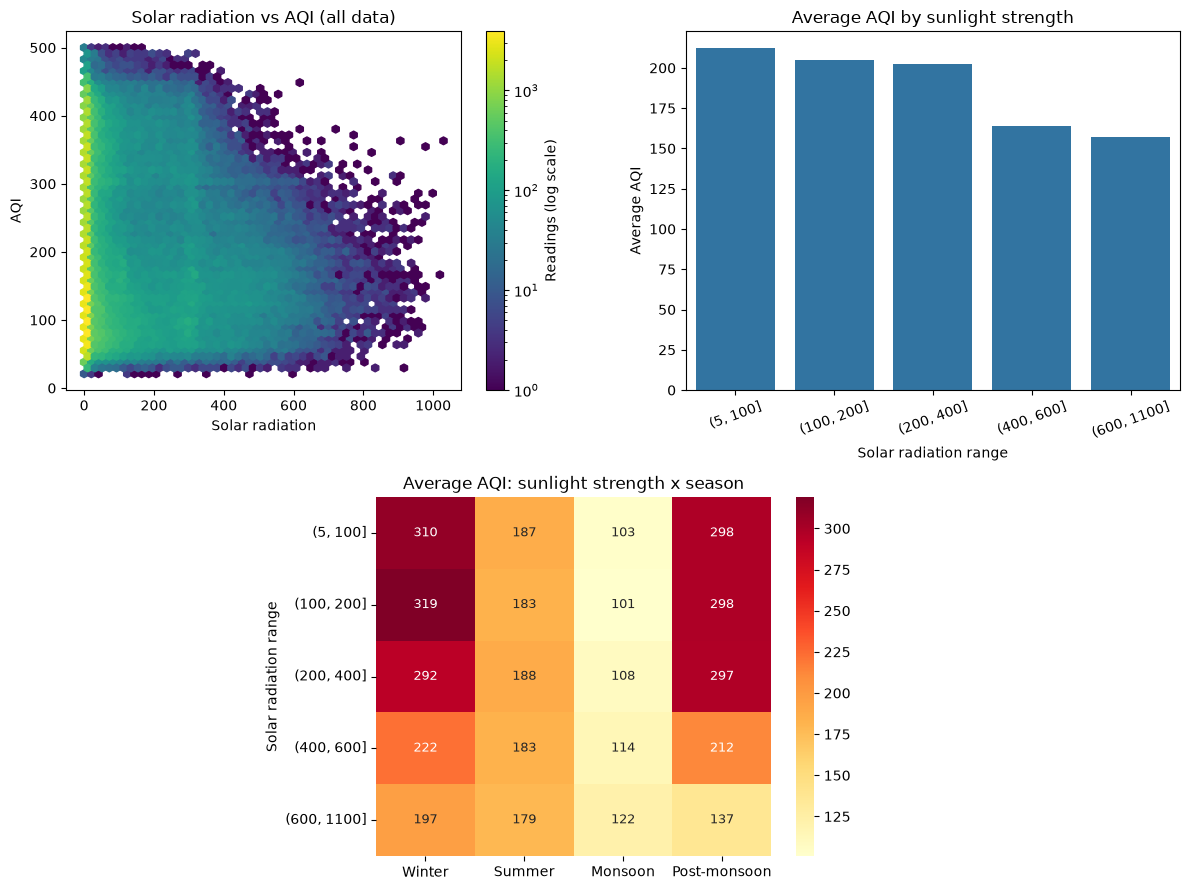

In [68]:


# ---------- SECTION 1: keep only rows where both columns exist ----------
# columns: solar_radiation, aqi -> drop rows where either one is missing
sun_aqi = df[["solar_radiation", "aqi", "Timestamp"]].dropna().copy()
print("Rows used:", len(sun_aqi))

# ---------- SECTION 2: how solar_radiation itself behaves ----------
# columns: solar_radiation, Timestamp -> average solar_radiation for each hour of the day
sun_aqi["hour"] = sun_aqi["Timestamp"].dt.hour
print(sun_aqi.groupby("hour")["solar_radiation"].mean().round(0))

# ---------- SECTION 3: overall correlation ----------
# columns: solar_radiation vs aqi -> Pearson (straight-line) and Spearman (rank-based)
print("Pearson :", round(sun_aqi["solar_radiation"].corr(sun_aqi["aqi"], method="pearson"), 2))
print("Spearman:", round(sun_aqi["solar_radiation"].corr(sun_aqi["aqi"], method="spearman"), 2))

# ---------- SECTION 4: sun vs no sun ----------
# column: solar_radiation -> 5 or less means "no sun" (night), more than 5 means "sun is up"
sun_aqi["sun_status"] = np.where(sun_aqi["solar_radiation"] > 5, "Sun is up", "No sun")
print(sun_aqi.groupby("sun_status")["aqi"].agg(["count", "mean", "median"]).round(1))

# ---------- SECTION 5: how strong the sunlight was (only when sun is up) ----------
# column: solar_radiation -> cut into ranges; then look at aqi inside each range
daytime = sun_aqi[sun_aqi["solar_radiation"] > 5].copy()
daytime["sun_range"] = pd.cut(daytime["solar_radiation"], bins=[5, 100, 200, 400, 600, 1100])
print(daytime.groupby("sun_range", observed=True)["aqi"].agg(["count", "mean", "median"]).round(1))

# ---------- SECTION 6: add season (from Timestamp) ----------
# column: Timestamp -> take the month, then map each month to a season
def get_season(month):
    if month in (12, 1, 2):
        return "Winter"
    elif month in (3, 4, 5):
        return "Summer"
    elif month in (6, 7, 8, 9):
        return "Monsoon"
    else:
        return "Post-monsoon"

daytime["season"] = daytime["Timestamp"].dt.month.map(get_season)

# columns: solar_radiation vs aqi -> correlation calculated separately for each season
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
for s in season_order:
    part = daytime[daytime["season"] == s]
    print(s, "| rows:", len(part),
          "| avg sun:", round(part["solar_radiation"].mean(), 0),
          "| avg aqi:", round(part["aqi"].mean(), 1),
          "| correlation:", round(part["solar_radiation"].corr(part["aqi"]), 2))

# columns: sun_range, season vs aqi -> average aqi, and also how many rows are behind each box
season_table = daytime.pivot_table(index="sun_range", columns="season", values="aqi",
                                   aggfunc="mean", observed=True)[season_order].round(0)
count_table = daytime.pivot_table(index="sun_range", columns="season", values="aqi",
                                  aggfunc="size", observed=True)[season_order]
print(season_table)
print(count_table)

# ---------- SECTION 7: plots (2 graphs on top, 1 graph below) ----------
fig = plt.figure(figsize=(12, 9))
grid = fig.add_gridspec(2, 4)

# GRAPH 1 (top left): hexbin
# columns: solar_radiation (x) vs aqi (y)
# What it shows: every hexagon is a group of readings, darker means more readings there.
# Look for: a clear slope. If the cloud is flat, sunlight alone does not move aqi much.
ax1 = fig.add_subplot(grid[0, 0:2])
hb = ax1.hexbin(sun_aqi["solar_radiation"], sun_aqi["aqi"], gridsize=50, cmap="viridis",
                mincnt=1, bins="log")
fig.colorbar(hb, ax=ax1, label="Readings (log scale)")
ax1.set_xlabel("Solar radiation", fontsize=10)
ax1.set_ylabel("AQI", fontsize=10)
ax1.set_title("Solar radiation vs AQI (all data)", fontsize=12)

# GRAPH 2 (top right): bar chart
# columns: sun_range vs aqi (only hours when the sun is up)
# What it shows: average aqi for each strength of sunlight.
# Look for: where the bars drop. The first bar also includes dawn, dusk and night readings.
ax2 = fig.add_subplot(grid[0, 2:4])
sns.barplot(data=daytime, x="sun_range", y="aqi", estimator="mean", errorbar=None, ax=ax2)
ax2.set_xlabel("Solar radiation range", fontsize=10)
ax2.set_ylabel("Average AQI", fontsize=10)
ax2.set_title("Average AQI by sunlight strength", fontsize=12)
ax2.tick_params(axis="x", rotation=20)

# GRAPH 3 (bottom, middle): heatmap
# columns: sun_range vs season, colour = average aqi
# What it shows: average aqi for each sunlight strength inside each season.
# Darker red means worse air.
# Look for: in which season does the colour get lighter as the sunlight gets stronger?
# Check count_table too, because boxes with few rows are less reliable.
ax3 = fig.add_subplot(grid[1, 1:3])
sns.heatmap(season_table, annot=True, fmt=".0f", cmap="YlOrRd", annot_kws={"size": 9}, ax=ax3)
ax3.set_title("Average AQI: sunlight strength x season", fontsize=12)
ax3.set_xlabel("")
ax3.set_ylabel("Solar radiation range", fontsize=10)

plt.tight_layout()
plt.show()

Descriptive Statistics:
                 aqi  atmospheric_pressure
count  179138.000000         179138.000000
mean      205.182373            981.857216
std       114.460665              9.621758
min        21.000000            930.500000
25%       108.000000            977.000000
50%       177.000000            982.500000
75%       303.000000            987.750000
max       500.000000           1010.000000

Correlation Analysis:
Pearson Correlation: 0.233
Spearman Correlation: 0.265


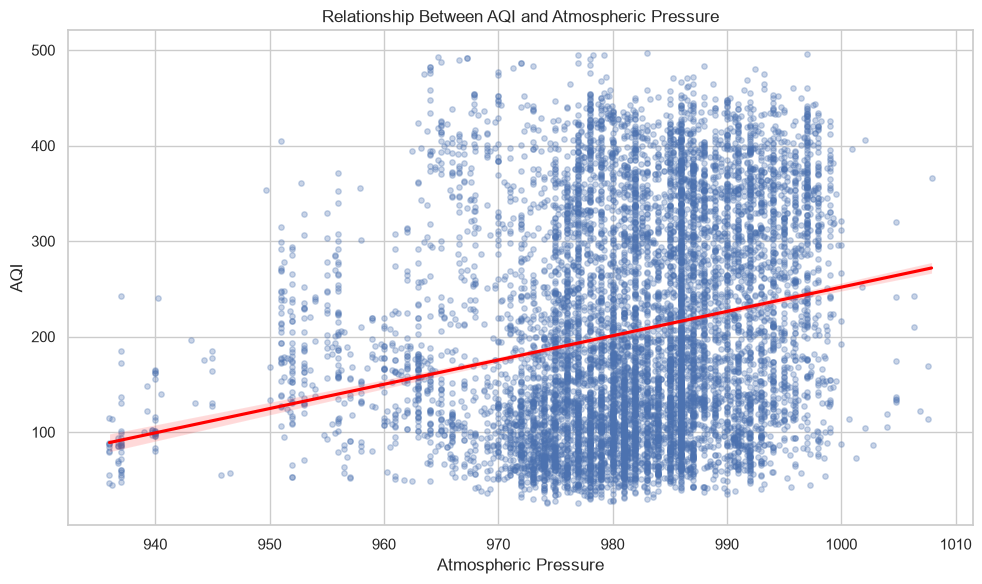


Monthly Comparison:
       average_aqi  average_pressure
month                               
1       319.357856        987.427043
2       222.003497        987.093956
3       172.059285        983.603784
4       208.996675        980.182725
5       164.986225        977.321917
6       140.128706        976.317148
7        79.478710        977.517904
8        90.665454        977.157666
9       108.402463        981.025278
10      229.495918        984.171406
11      362.976230        986.166764
12      360.756290        984.921998


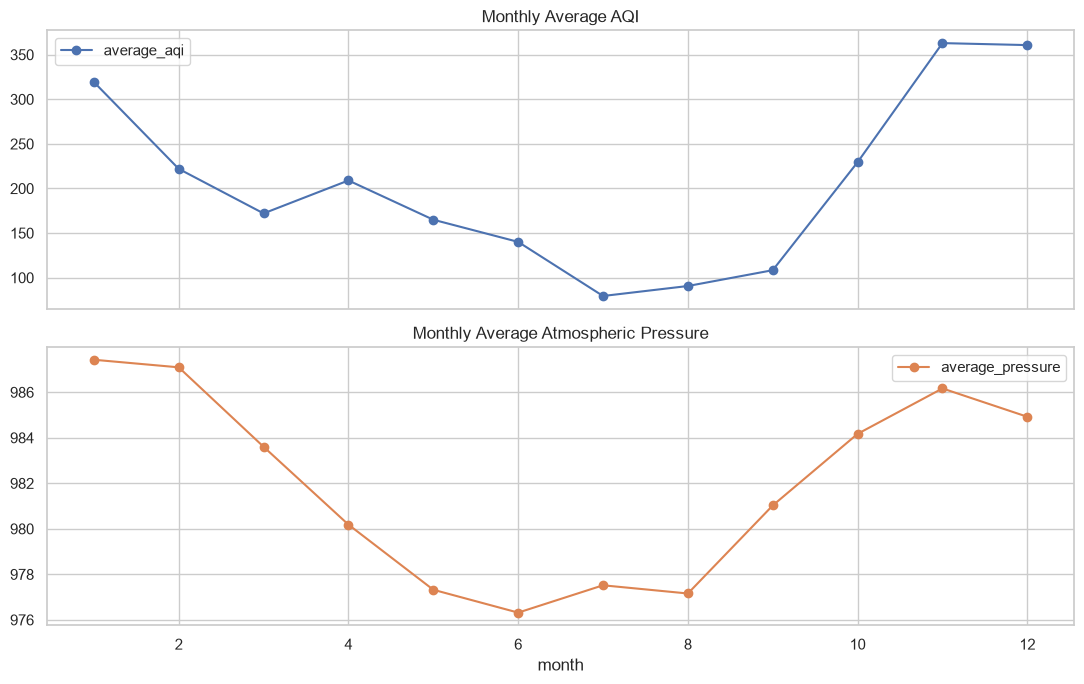

In [71]:

# ==========================================
# BIVARIATE ANALYSIS: AQI vs ATMOSPHERIC PRESSURE
# ==========================================

# Selecting the required columns
bivariate_df = df[['aqi', 'atmospheric_pressure', 'Timestamp']].copy()

# Removing missing observations from the selected variables
bivariate_df.dropna(inplace=True)

# 1. Descriptive statistics to understand the distribution of both variables
print("Descriptive Statistics:")
print(bivariate_df[['aqi', 'atmospheric_pressure']].describe())


# 2. Calculating Pearson and Spearman correlation to identify
# the strength and direction of the relationship
from scipy.stats import pearsonr, spearmanr

pearson_corr, pearson_p = pearsonr(
    bivariate_df['aqi'],
    bivariate_df['atmospheric_pressure']
)

spearman_corr, spearman_p = spearmanr(
    bivariate_df['aqi'],
    bivariate_df['atmospheric_pressure']
)

print("\nCorrelation Analysis:")
print("Pearson Correlation:", round(pearson_corr, 3))
print("Spearman Correlation:", round(spearman_corr, 3))


# 3. Visualizing the relationship using a scatter plot and trend line
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.regplot(
    data=bivariate_df.sample(
        n=min(10000, len(bivariate_df)),
        random_state=42
    ),
    x='atmospheric_pressure',
    y='aqi',
    scatter_kws={'alpha': 0.3, 's': 15},
    line_kws={'color': 'red'}
)

plt.title('Relationship Between AQI and Atmospheric Pressure')
plt.xlabel('Atmospheric Pressure')
plt.ylabel('AQI')
plt.tight_layout()
plt.show()


# 4. Comparing average AQI across months to understand
# temporal variations in the relationship
bivariate_df['month'] = (
    bivariate_df['Timestamp'].dt.month
)

monthly_analysis = (
    bivariate_df.groupby('month')
    .agg(
        average_aqi=('aqi', 'mean'),
        average_pressure=('atmospheric_pressure', 'mean')
    )
)

print("\nMonthly Comparison:")
print(monthly_analysis)


# Visualizing monthly variations in AQI and atmospheric pressure
monthly_analysis.plot(
    kind='line',
    subplots=True,
    figsize=(11, 7),
    marker='o',
    title=[
        'Monthly Average AQI',
        'Monthly Average Atmospheric Pressure'
    ]
)

plt.tight_layout()
plt.show()


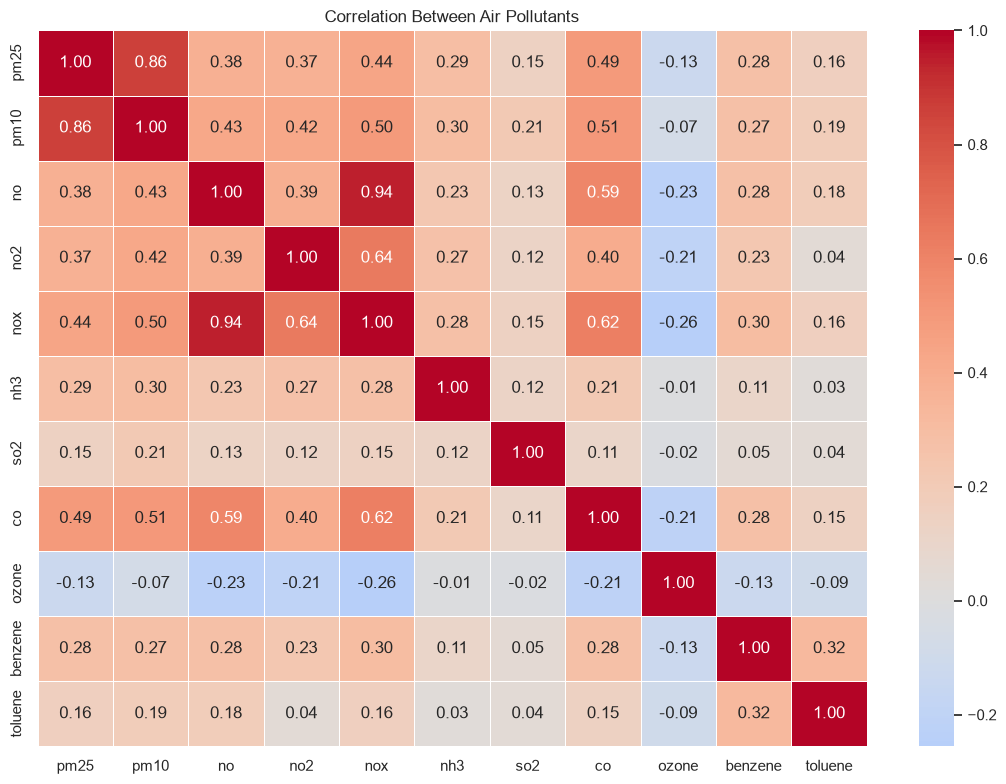

In [72]:

# ==========================================
# 1. POLLUTANT CORRELATION ANALYSIS
# ==========================================

# Selecting pollutant columns
pollutants = [
    'pm25', 'pm10', 'no', 'no2', 'nox',
    'nh3', 'so2', 'co', 'ozone', 'benzene', 'toluene'
]

# Calculating pairwise correlations between pollutants
pollutant_corr = df[pollutants].corr(method='pearson')

# Visualizing pollutant correlations
plt.figure(figsize=(11, 8))

sns.heatmap(
    pollutant_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Correlation Between Air Pollutants')
plt.tight_layout()
plt.show()


                pm25    pm10     no    no2    nox    nh3    so2    co  ozone  benzene  toluene
aqi_category                                                                                  
Good           19.00   43.50   5.88  19.23  15.32  26.17   6.98  0.63  20.79     0.40     2.84
Satisfactory   29.00   73.00   7.99  25.95  20.08  26.12   8.56  0.80  20.62     0.75     3.62
Moderate       52.66  144.50   9.35  34.96  27.29  32.54  10.80  0.88  26.40     1.02     4.18
Poor           98.79  229.00  13.12  46.65  36.83  38.40  13.00  1.11  22.95     1.44     6.35
Very Poor     174.00  300.75  17.82  52.57  45.13  43.00  12.38  1.41  15.95     1.83     9.30
Severe        281.99  427.00  21.70  60.15  54.00  46.65  13.38  1.89  12.84     2.39    14.98


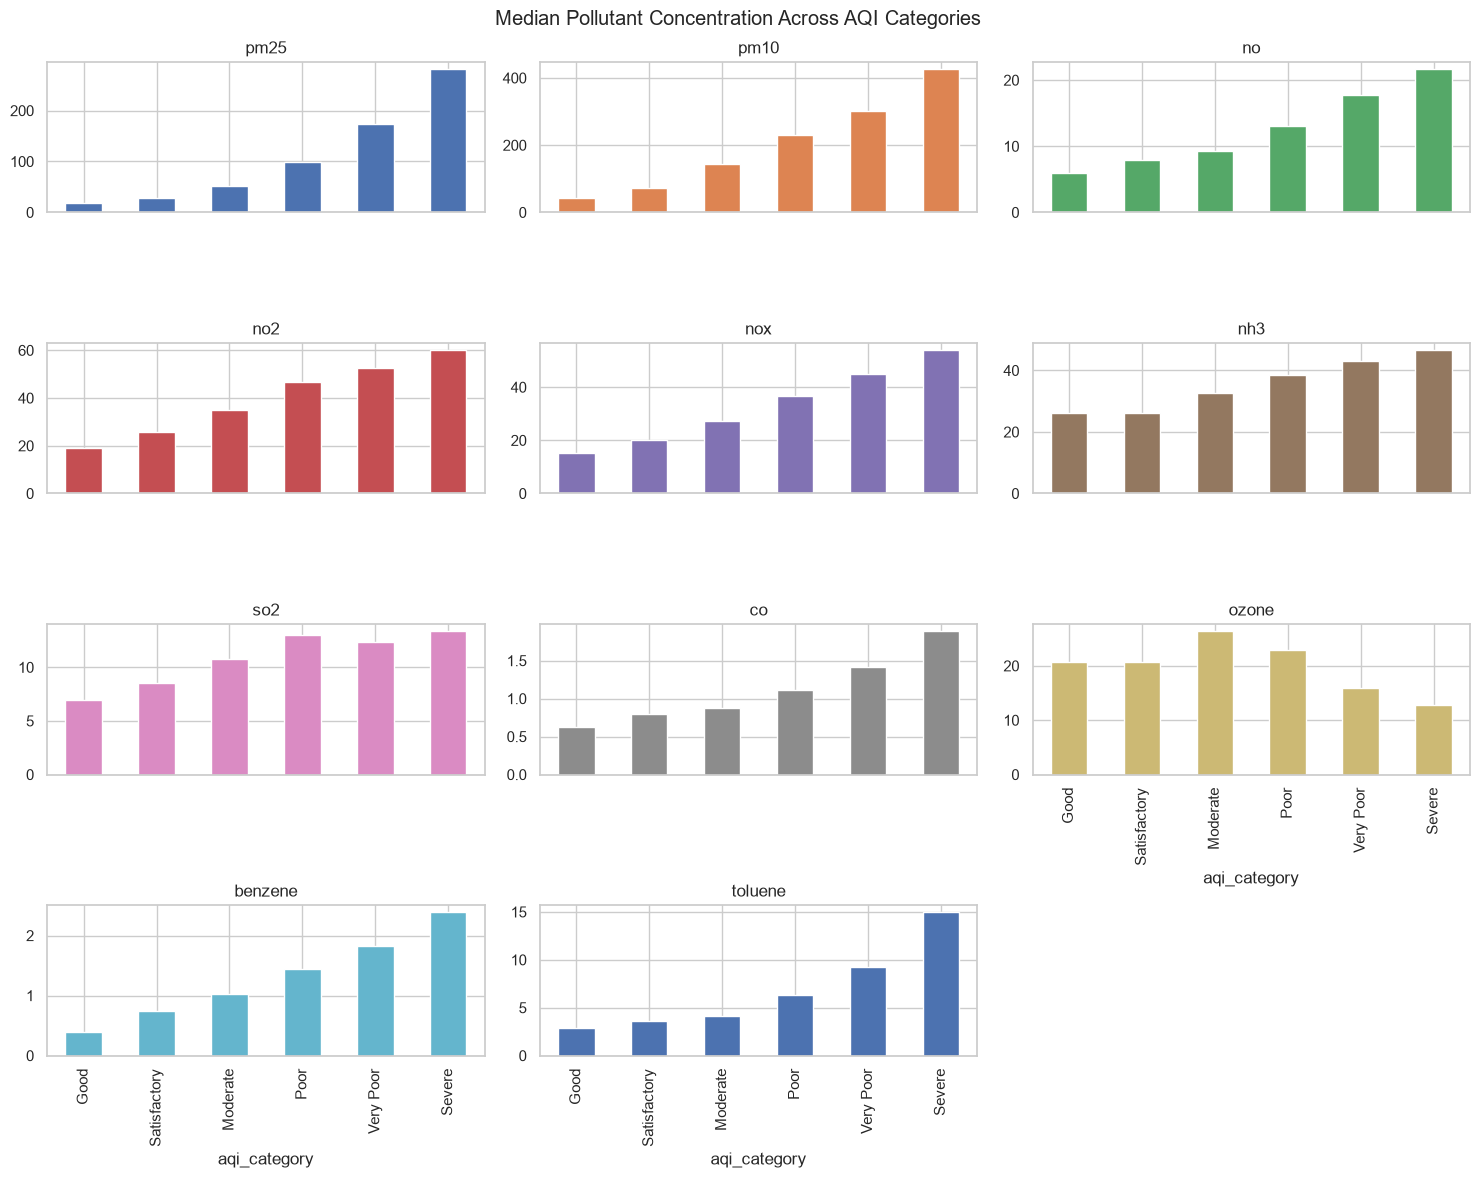

In [73]:

# ==========================================
# 2. POLLUTANT ANALYSIS BY AQI CATEGORY
# ==========================================

# Selecting pollutant columns and AQI category
pollutant_df = df[['aqi_category'] + pollutants].copy()

# Comparing pollutant concentrations across AQI categories
category_analysis = (
    pollutant_df.groupby('aqi_category', observed=True)[pollutants]
    .median()
    .round(2)
)

print(category_analysis)

# Visualizing median pollutant concentrations across AQI categories
category_analysis.plot(
    kind='bar',
    subplots=True,
    layout=(4, 3),
    figsize=(15, 12),
    legend=False,
    sharex=True
)

plt.suptitle('Median Pollutant Concentration Across AQI Categories')
plt.tight_layout()
plt.show()


In [74]:

# ==========================================
# 3. STATION-WISE DATA RELIABILITY
# ==========================================

# Calculating observation coverage and AQI availability for each station
station_quality = (
    df.groupby(['station_id', 'station_name'])
    .agg(
        first_record=('Timestamp', 'min'),
        last_record=('Timestamp', 'max'),
        total_records=('Timestamp', 'size'),
        available_aqi=('aqi', 'count'),
        unique_hours=('Timestamp', 'nunique')
    )
    .reset_index()
)

# Calculating expected hourly observations within each station's recorded period
station_quality['expected_hours'] = (
    (station_quality['last_record'] -
     station_quality['first_record']).dt.total_seconds() / 3600
).round() + 1

# Calculating missing AQI percentage and timestamp coverage
station_quality['missing_aqi_pct'] = (
    (1 - station_quality['available_aqi'] /
     station_quality['total_records']) * 100
).round(2)

station_quality['coverage_pct'] = (
    station_quality['unique_hours'] /
    station_quality['expected_hours'] * 100
).round(2)

# Displaying stations with the lowest data coverage
print(
    station_quality.sort_values('coverage_pct')[
        ['station_name', 'total_records', 'missing_aqi_pct', 'coverage_pct']
    ].to_string(index=False)
)


                      station_name  total_records  missing_aqi_pct  coverage_pct
                 CRRI Mathura Road           8760             9.36         100.0
                   Burari Crossing           8760            18.61         100.0
                   North Campus DU           8760            14.94         100.0
                    IGI Airport T3           8760            24.86         100.0
                       Pusa (IITM)           8760            22.53         100.0
                         Aya Nagar           8760            13.30         100.0
                    IMD Lodhi Road           8760            28.11         100.0
                          Shadipur           8760             5.64         100.0
              IHBAS Dilshad Garden           8760             9.70         100.0
                       NSIT Dwarka           8760             4.73         100.0
                               ITO           8760             8.36         100.0
                            

In [75]:

# ==========================================
# 4. EXTREME POLLUTION EPISODE ANALYSIS
# ==========================================

# Selecting AQI and particulate matter observations
episode_df = df[
    ['station_id', 'station_name', 'Timestamp', 'aqi', 'pm25', 'pm10']
].dropna(subset=['Timestamp', 'aqi']).copy()

# Sorting observations station-wise by timestamp
episode_df = episode_df.sort_values(
    ['station_id', 'Timestamp']
).reset_index(drop=True)

# Identifying severe pollution observations
episode_df['severe'] = episode_df['aqi'] >= 401

# Identifying the beginning of each consecutive severe pollution episode
previous_time = episode_df.groupby('station_id')['Timestamp'].shift()
previous_severe = episode_df.groupby('station_id')['severe'].shift().fillna(False)

episode_df['new_episode'] = (
    episode_df['severe'] &
    (
        ~previous_severe |
        ((episode_df['Timestamp'] - previous_time) != pd.Timedelta(hours=1))
    )
)

# Assigning episode numbers separately to each monitoring station
episode_df['episode_no'] = (
    episode_df.groupby('station_id')['new_episode'].cumsum()
)

# Summarizing each severe pollution episode
episodes = (
    episode_df[episode_df['severe']]
    .groupby(['station_id', 'station_name', 'episode_no'])
    .agg(
        start=('Timestamp', 'min'),
        end=('Timestamp', 'max'),
        duration_hours=('Timestamp', 'size'),
        average_aqi=('aqi', 'mean'),
        maximum_aqi=('aqi', 'max'),
        average_pm25=('pm25', 'mean'),
        average_pm10=('pm10', 'mean')
    )
    .round(1)
    .reset_index()
)

# Displaying the ten longest severe pollution episodes
print(
    episodes.sort_values(
        ['duration_hours', 'maximum_aqi'],
        ascending=False
    ).head(10).to_string(index=False)
)


 station_id station_name  episode_no               start                 end  duration_hours  average_aqi  maximum_aqi  average_pm25  average_pm10
       1423 Jahangirpuri         632 2025-12-15 06:00:00 2025-12-15 06:00:00               1        500.0        500.0         476.0         555.0
       1423 Jahangirpuri         633 2025-12-15 07:00:00 2025-12-15 07:00:00               1        500.0        500.0         353.0         412.0
       5024       Alipur          17 2025-03-14 21:00:00 2025-03-14 21:00:00               1        500.0        500.0          38.0          45.0
       5024       Alipur          19 2025-03-15 05:00:00 2025-03-15 05:00:00               1        500.0        500.0          13.0          31.0
       1420  Ashok Vihar         502 2025-12-14 17:00:00 2025-12-14 17:00:00               1        499.0        499.0         576.0         837.0
       1420  Ashok Vihar         503 2025-12-14 18:00:00 2025-12-14 18:00:00               1        499.0        499.0

C:\Users\Keshav\AppData\Local\Temp\ipykernel_6672\3295992274.py:48: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(1)
